# State of Data Brasil — Tech Challenge Fase 3
## Engenharia de Dados e Analytics para uma instituição financeira

**Universo analítico:** respostas de residentes no Brasil, por edição, após remoção de duplicatas exatas.

Pipeline cloud está em `codigos/glue_job.py`.

In [1]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
from IPython.display import display, Image
BASE = Path.cwd()
if not (BASE / 'codigos').exists():
    raise RuntimeError('Abra o notebook a partir da pasta principal entrega/.')
sys.path.insert(0, str(BASE / 'codigos'))
from analise_local import run
silver = run(BASE / 'dados_originais', BASE / 'resultados')
brasil = silver[silver.vive_no_brasil.eq(1)].copy()
distribuicoes = pd.read_csv(BASE/'resultados/distribuicoes.csv', dtype={'edicao_pesquisa':str})
indicadores = pd.read_csv(BASE/'resultados/indicadores.csv', dtype={'edicao_pesquisa':str})
salarios = pd.read_csv(BASE/'resultados/salarios_segmentos.csv', dtype={'edicao_pesquisa':str})
print('Linhas Silver:', len(silver))
print('Respostas residentes no Brasil:', len(brasil))

   edicao  linhas_csv  colunas_csv  duplicatas_exatas  linhas_silver  residentes_brasil  salarios_anomalos  ia_conflitante  idades_invalidas
     2023        5293          399                  0           5293               5172                  1              26                 0
     2024        5217          403                  2           5215               5076                  0              13                 0
2025-2026        3495          388                  1           3494               3372                  1               5                 0


Linhas Silver: 14002
Respostas residentes no Brasil: 13620


## 1. Qualidade e rastreabilidade
As contagens se referem a respostas por edição, não pessoas únicas em três anos. Somente duplicatas inteiramente idênticas são removidas. Salários malformados não são corrigidos por suposição; conflitos de IA são excluídos apenas do índice de uso.

In [2]:
display(pd.read_csv(BASE/'resultados/qualidade.csv'))
display(pd.read_csv(BASE/'resultados/anomalias_salariais.csv'))
display(pd.read_csv(BASE/'resultados/dicionario_mapeamento.csv').head(12))

,edicao,linhas_csv,colunas_csv,duplicatas_exatas,linhas_silver,residentes_brasil,salarios_anomalos,ia_conflitante,idades_invalidas
0,2023,5293,399,0,5293,5172,1,26,0
1,2024,5217,403,2,5215,5076,0,13,0
2,2025-2026,3495,388,1,3494,3372,1,5,0


,edicao_pesquisa,faixa_salarial_original,arquivo_origem
0,2023,de R$ 101/mês a R$ 2.000/mês,State_of_data_BR_2023_Kaggle - df_survey_2023.csv
1,2025-2026,de R$ 25.001/mês a R$ 3000/mês,Final Dataset - State of Data 2025-2026 - Kagg...


,edicao,campo_destino,coluna_origem,observacao
0,2023,id_resposta,"('P0', 'id')",Mapeamento por significado do campo; preservar...
1,2023,idade,"('P1_a ', 'Idade')",Mapeamento por significado do campo; preservar...
2,2023,genero,"('P1_b ', 'Genero')",Mapeamento por significado do campo; preservar...
3,2023,raca,"('P1_c ', 'Cor/raca/etnia')",Mapeamento por significado do campo; preservar...
4,2023,pcd,"('P1_d ', 'PCD')",Mapeamento por significado do campo; preservar...
5,2023,vive_no_brasil,"('P1_g ', 'vive_no_brasil')",Mapeamento por significado do campo; preservar...
6,2023,uf,"('P1_i_1 ', 'uf onde mora')",Mapeamento por significado do campo; preservar...
7,2023,regiao,"('P1_i_2 ', 'Regiao onde mora')",Mapeamento por significado do campo; preservar...
8,2023,escolaridade,"('P1_l ', 'Nivel de Ensino')",Mapeamento por significado do campo; preservar...
9,2023,situacao_trabalho,"('P2_a ', 'Qual sua situação atual de trabalho?')",Mapeamento por significado do campo; preservar...


## 2. Spark: mesmo contrato, implementação distribuída
O teste incluído usa `silver_one` e `gold_tables`, as mesmas funções chamadas pelo Glue Job. Ele confere todas as categorias e contagens dos resultados, além da escrita e releitura Parquet.
A saída abaixo é o relatório real do teste já realizado.

In [3]:
REPETIR_TESTE_SPARK = False
if REPETIR_TESTE_SPARK:
    processo = subprocess.run([sys.executable, str(BASE/'codigos/validar_spark_local.py'),
                              str(BASE/'dados_originais'), str(BASE/'resultados')],
                              capture_output=True, text=True, check=True)
    print(processo.stdout)
print((BASE/'resultados/validacao_spark.txt').read_text())

PASS: distribuicoes: 290 linhas; todas as categorias, contagens e percentuais equivalentes.
PASS: indicadores: 45 linhas; todas as categorias, contagens e percentuais equivalentes.
PASS: salarios_segmentos: 159 linhas; todas as categorias, contagens e percentuais equivalentes.
PASS: relatório de qualidade equivalente; leitura Spark preservou linhas e campos mapeados.
PASS: escrita e releitura Parquet Spark: 14.002 registros.

Spark 3.5.6; execução local, não AWS.



### Transformação Spark para uma edição — exemplo de uso
O código abaixo documenta o ponto de entrada para execução interativa em um notebook Spark. Mantê-lo desativado evita abrir outra sessão durante a leitura dos resultados.


In [4]:
EXECUTAR_EXEMPLO_SPARK = False
if EXECUTAR_EXEMPLO_SPARK:
    from pyspark.sql import SparkSession
    from glue_job import silver_one, gold_tables
    spark = SparkSession.builder.master('local[2]').appName('TechChallenge').getOrCreate()
    cfg = json.loads((BASE/'codigos/config_pipeline.json').read_text())
    frames = []
    for edicao, arquivo in cfg['fontes'].items():
        frame, qualidade = silver_one(spark, str(BASE/'dados_originais'/arquivo), edicao, cfg)
        frames.append(frame)
        print(qualidade)
    consolidada = frames[0]
    for frame in frames[1:]:
        consolidada = consolidada.unionByName(frame)
    for nome, tabela in gold_tables(consolidada, cfg).items():
        print(nome, tabela.count())
        tabela.show(5, truncate=False)
    spark.stop()

## 3. Estrutura, diversidade e modelos de trabalho
Cada percentual tem o denominador da pergunta. As amostras não são um painel. Não extrapolamos para participação nacional no emprego.

,edicao_pesquisa,dimensao,categoria,n,denominador,percentual
0,2023,genero,Masculino,3883,5172,75.077340
1,2023,genero,Feminino,1265,5172,24.458623
2,2023,genero,Prefiro não informar,15,5172,0.290023
3,2023,genero,Outro,9,5172,0.174014
96,2024,genero,Masculino,3864,5076,76.122931
97,2024,genero,Feminino,1190,5076,23.443656
98,2024,genero,Prefiro não informar,14,5076,0.275808
99,2024,genero,Outro,8,5076,0.157604
190,2025-2026,genero,Masculino,2612,3372,77.461447
191,2025-2026,genero,Feminino,742,3372,22.004745


,edicao_pesquisa,dimensao,categoria,n,denominador,percentual
194,2025-2026,regiao,Sudeste,2170,3369,64.410804
195,2025-2026,regiao,Sul,540,3369,16.028495
196,2025-2026,regiao,Nordeste,380,3369,11.279311
197,2025-2026,regiao,Centro-oeste,231,3369,6.856634
198,2025-2026,regiao,Norte,48,3369,1.424755


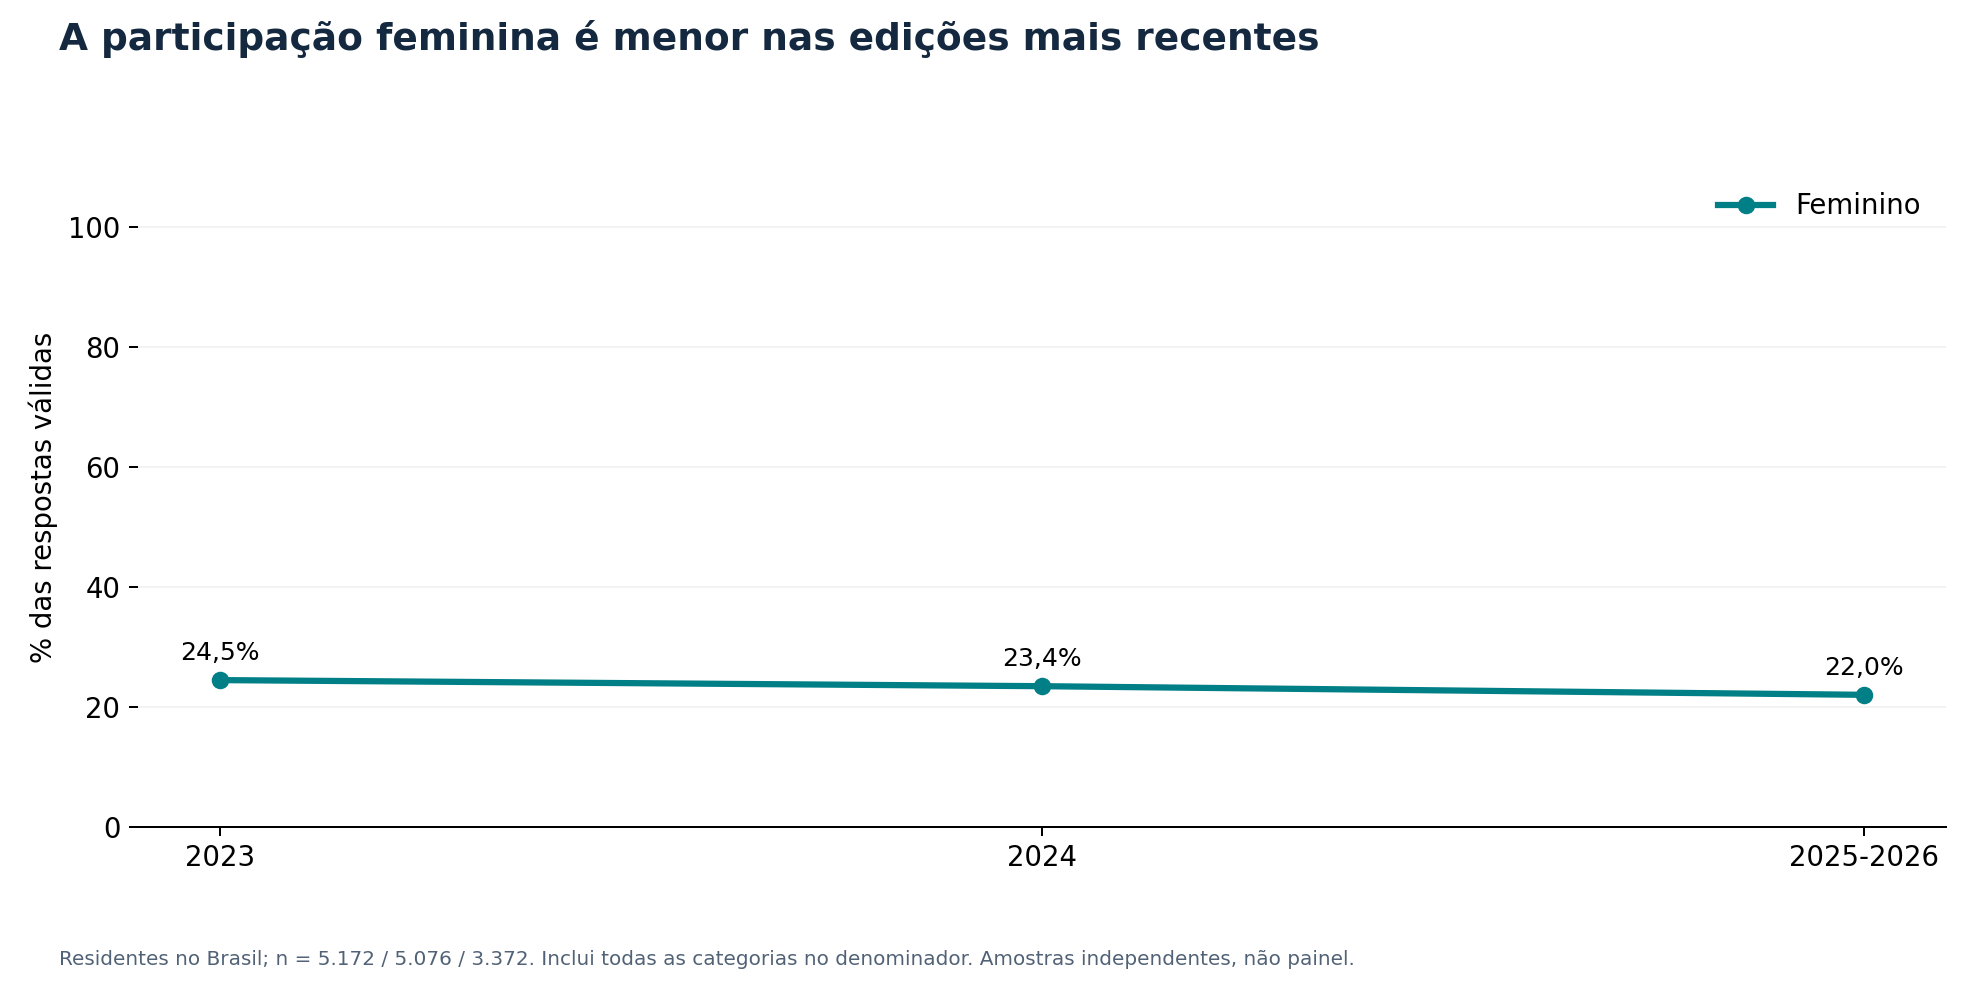

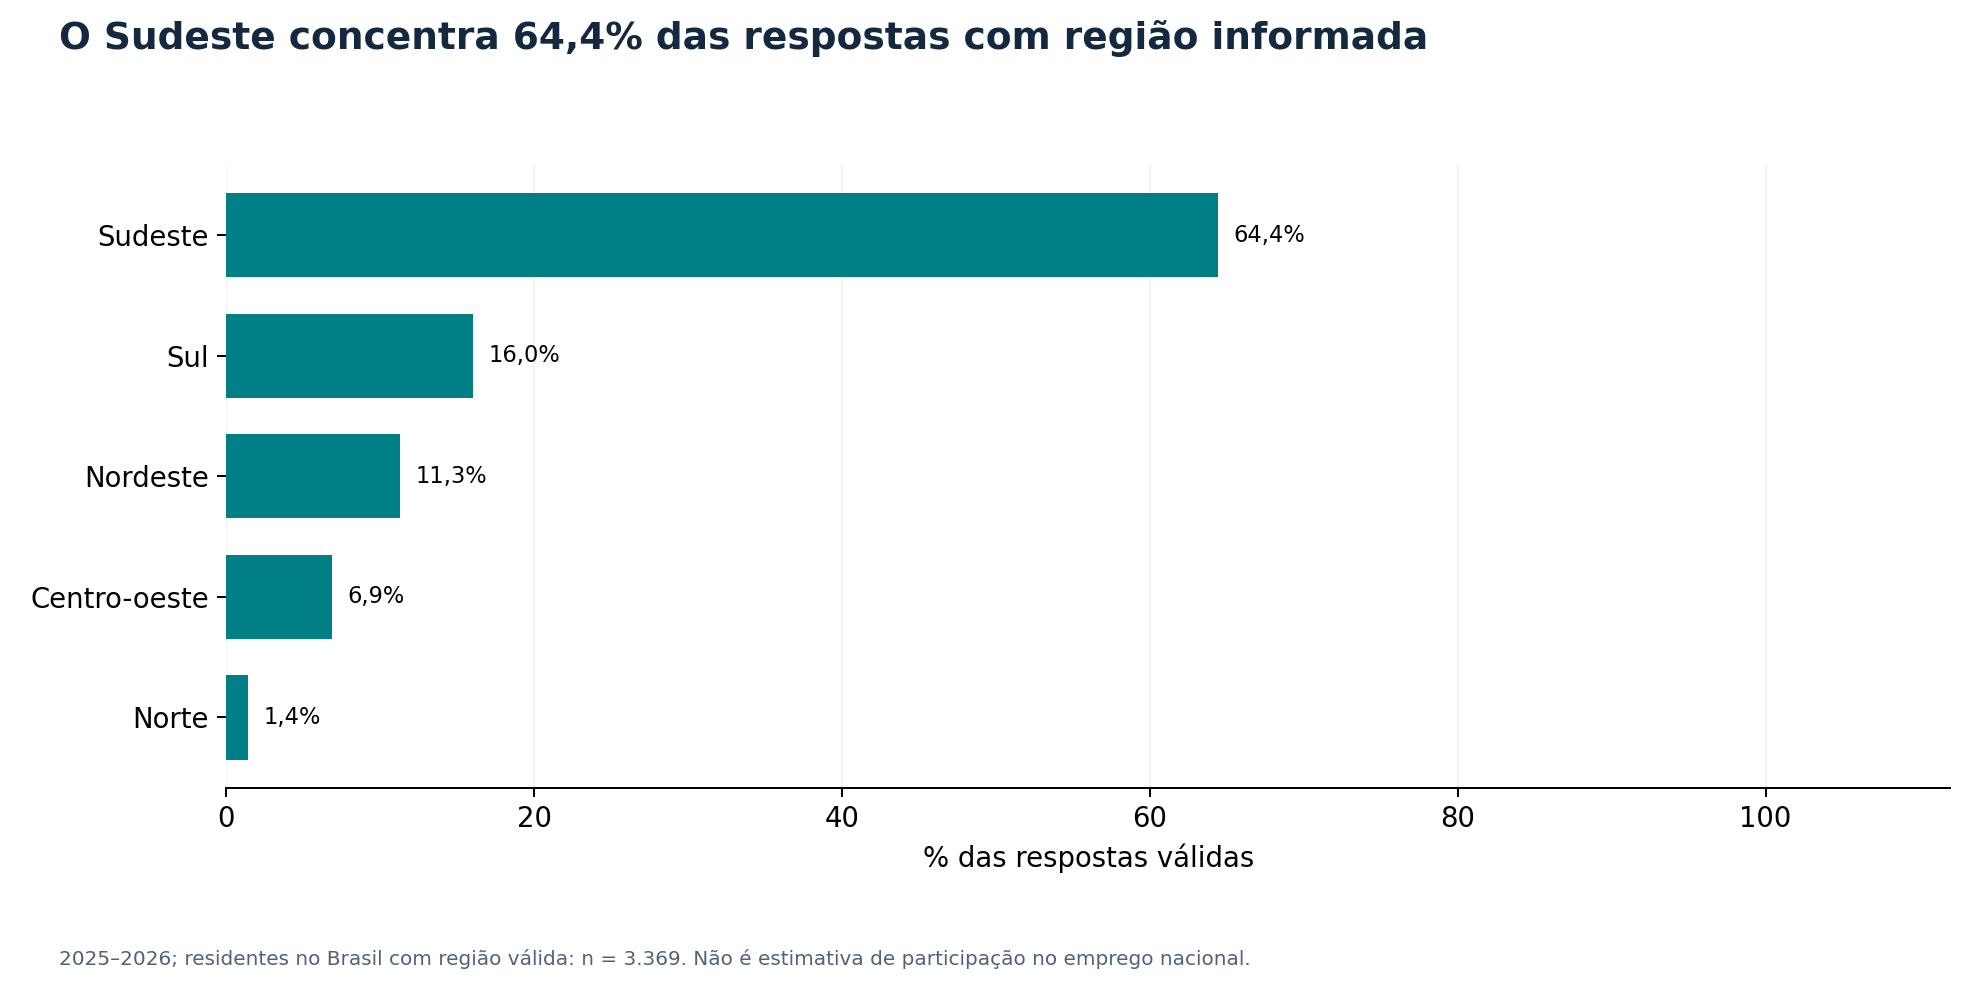

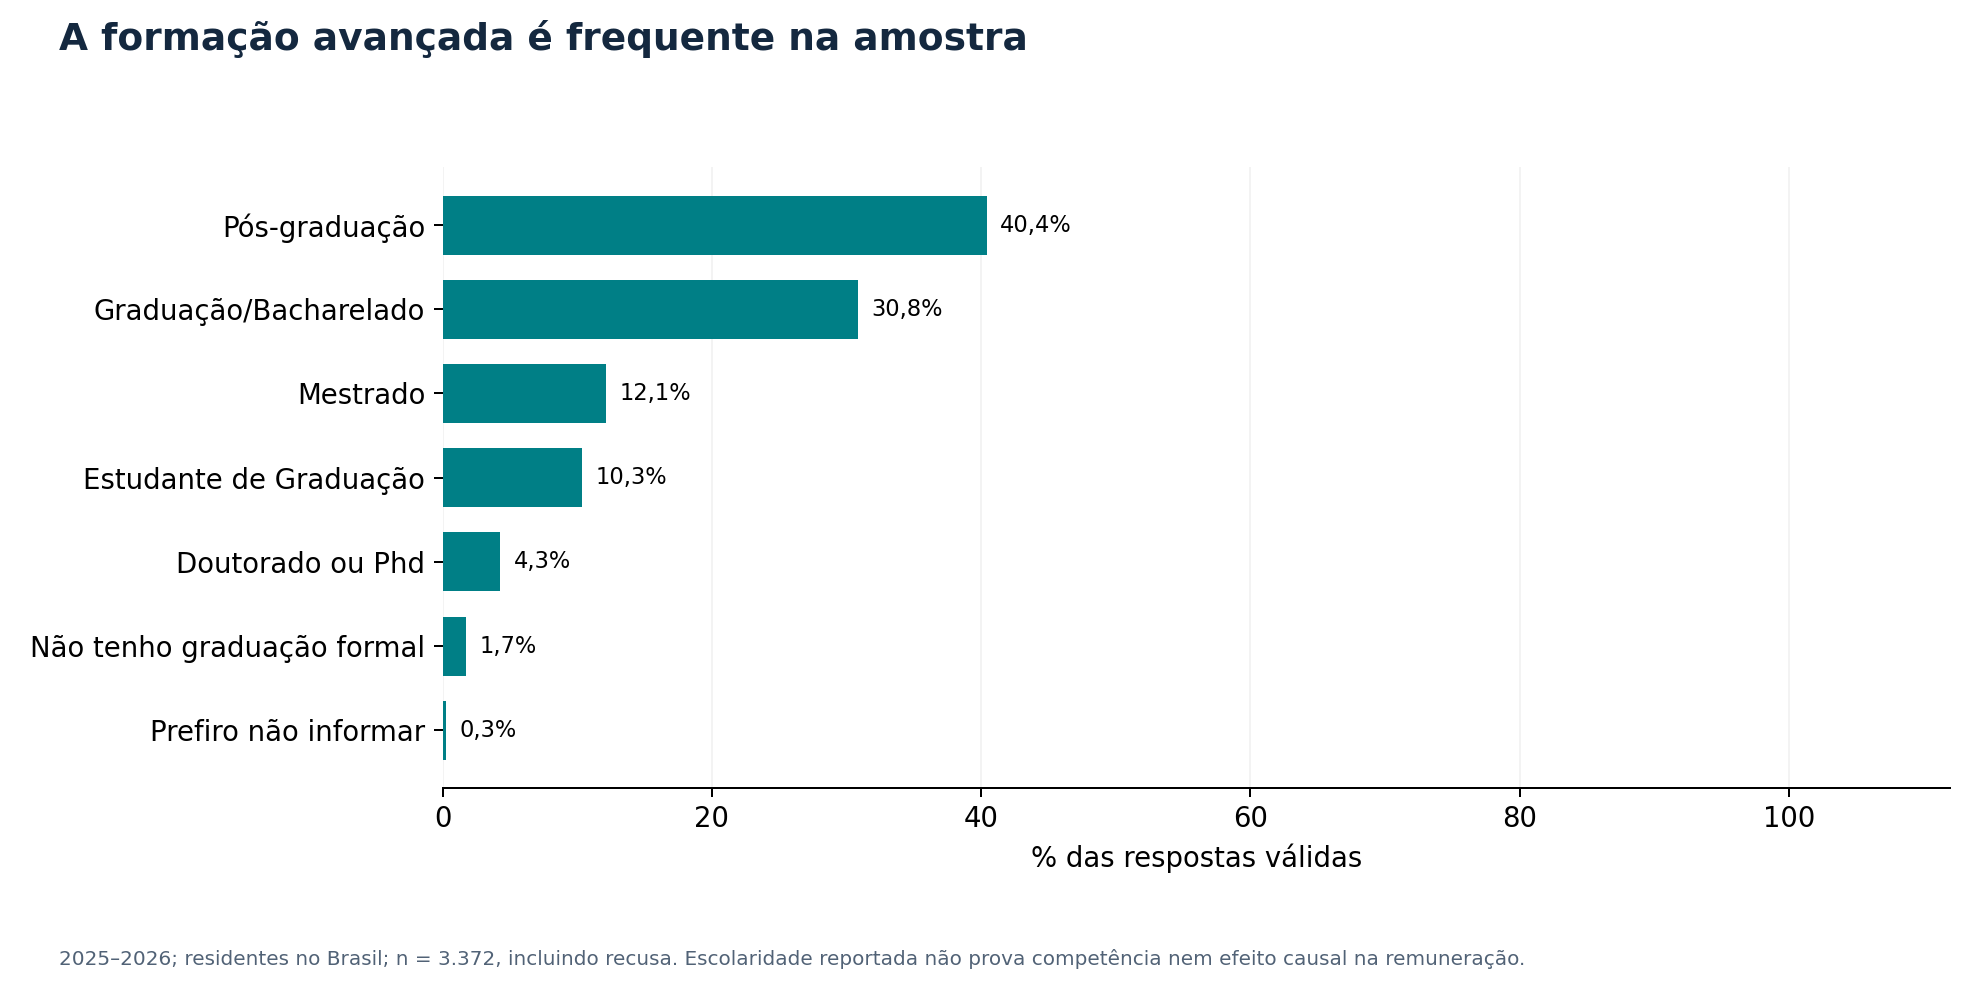

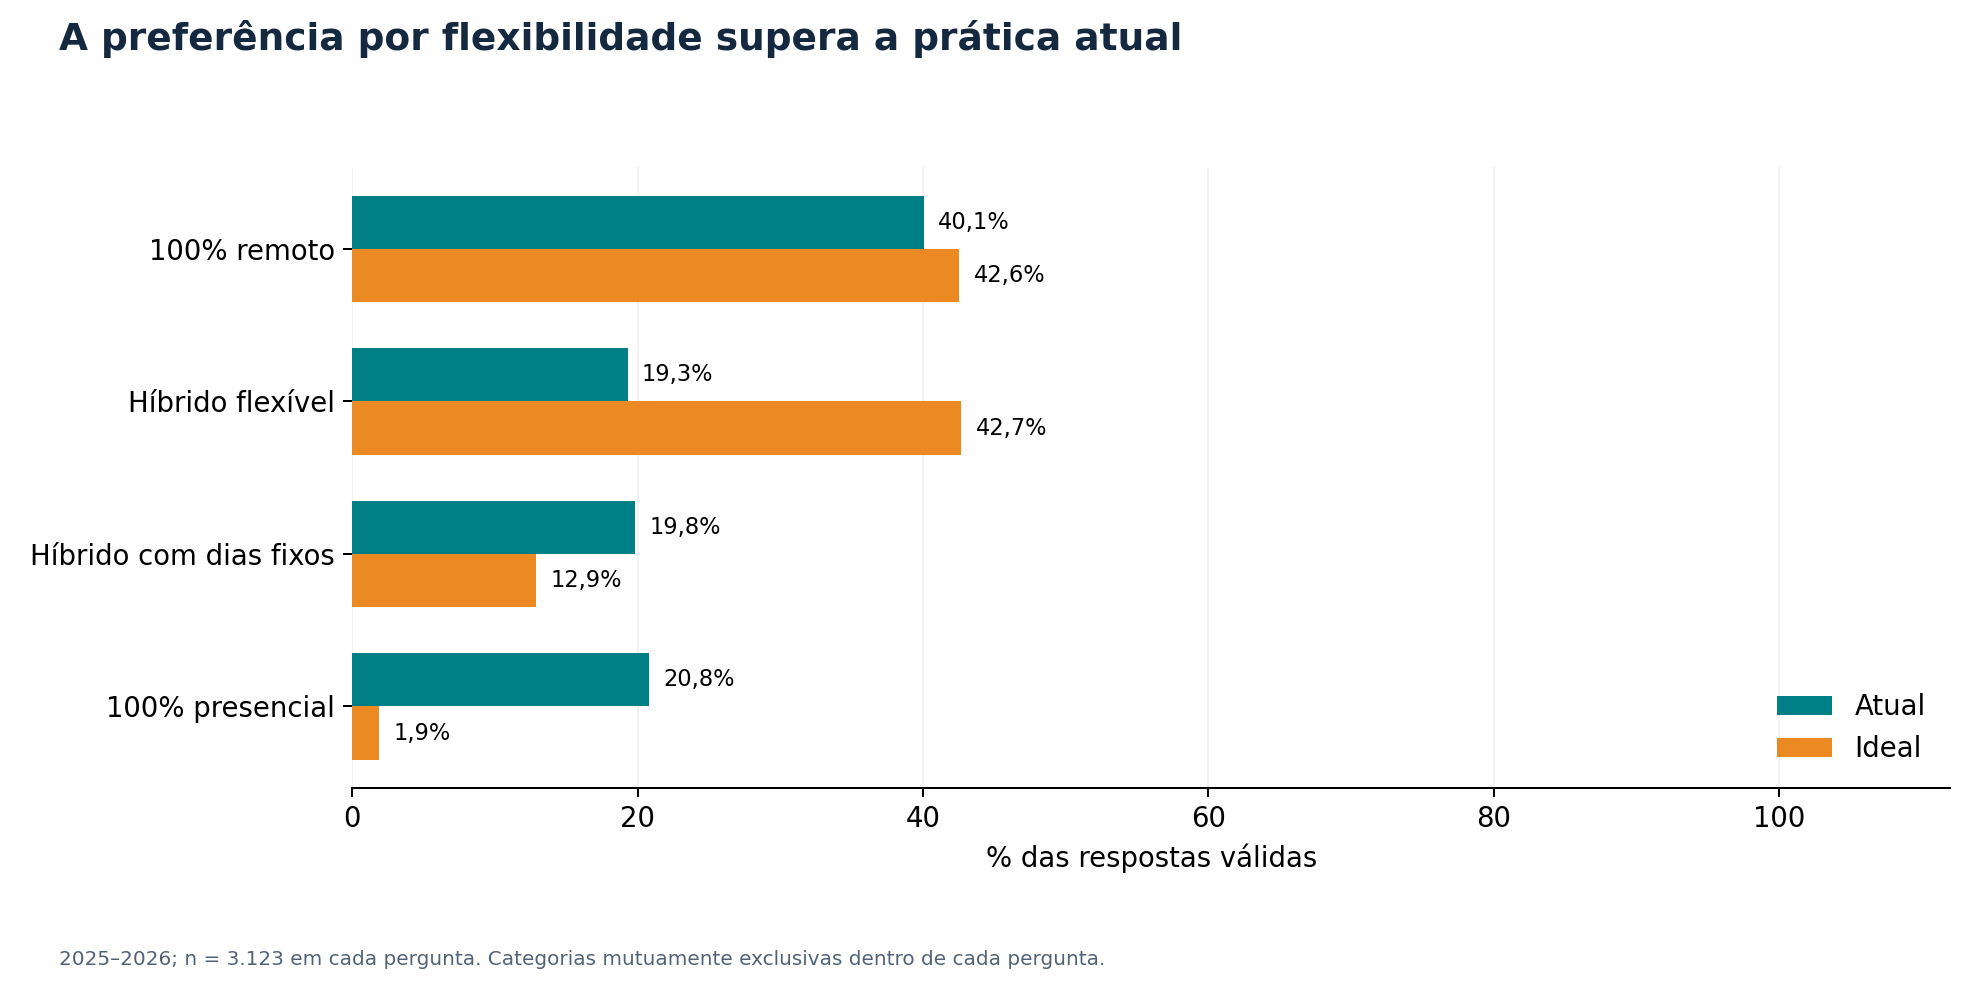

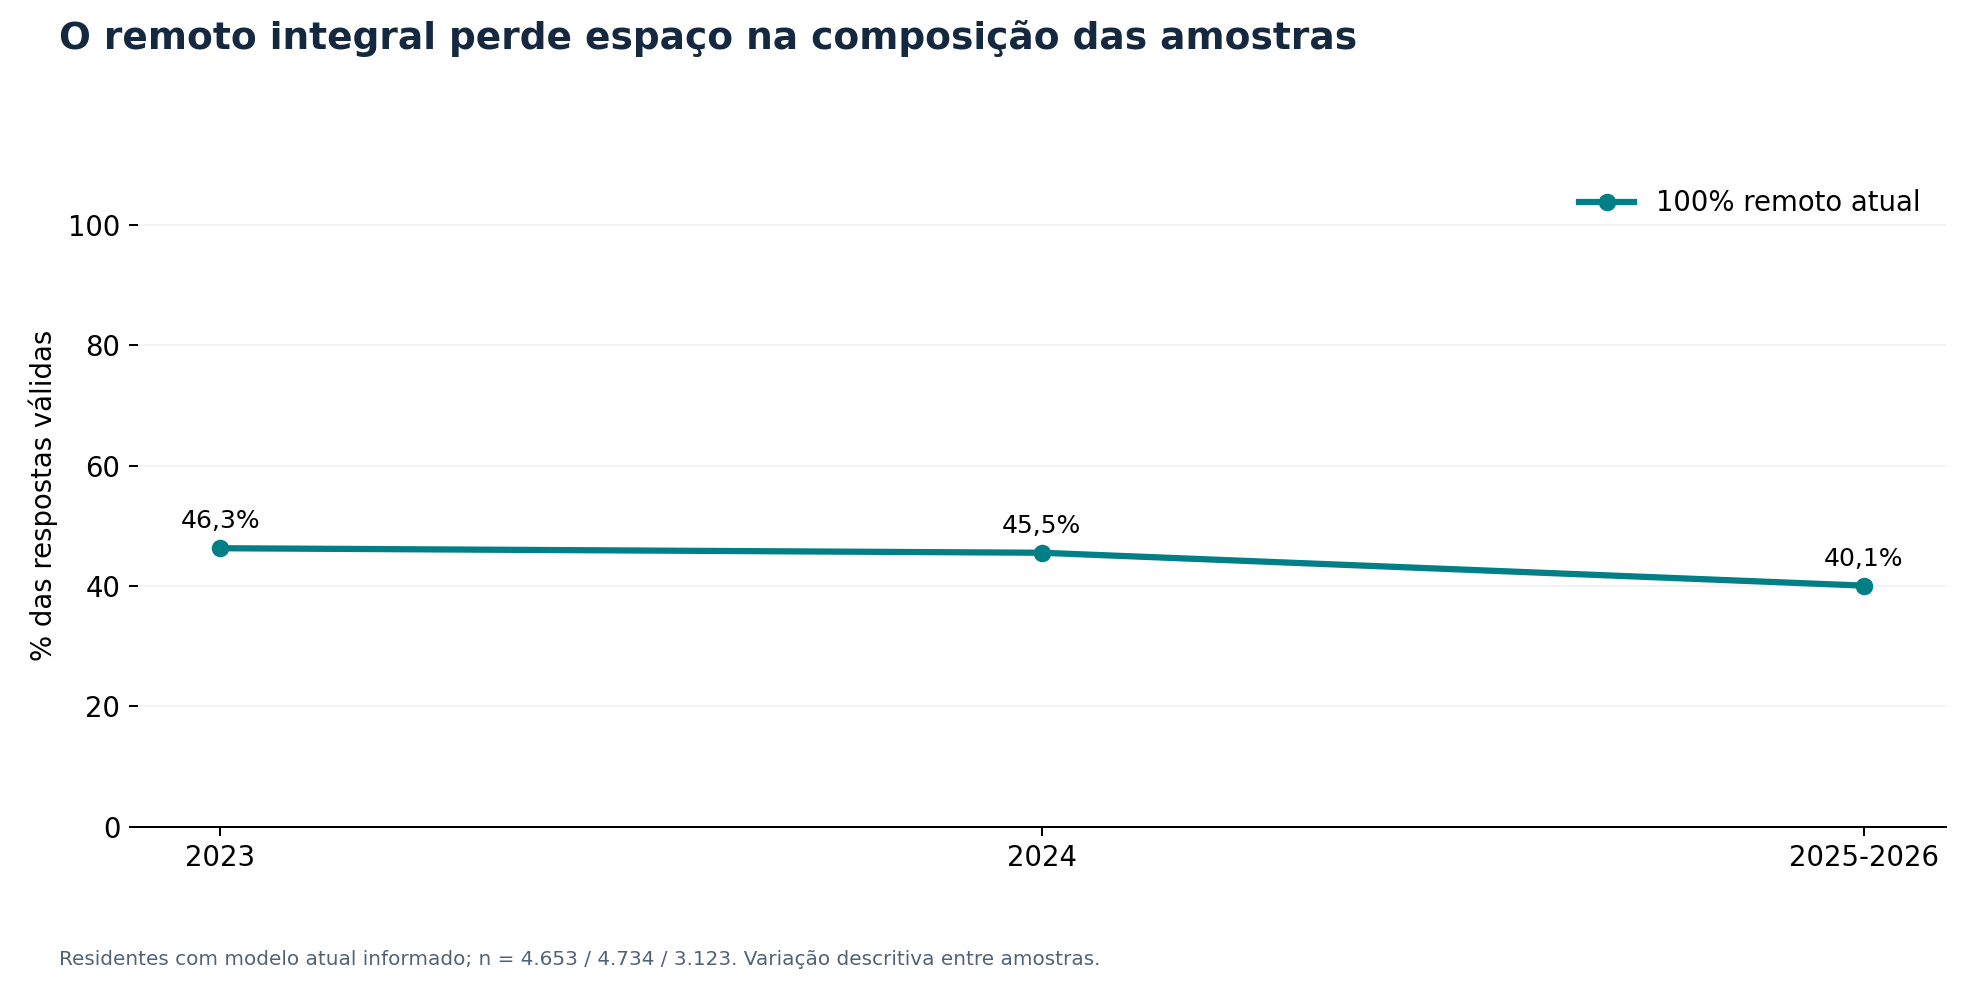

In [5]:
display(distribuicoes.query("dimensao == 'genero'"))
display(distribuicoes.query("edicao_pesquisa == '2025-2026' and dimensao == 'regiao'"))
for nome in ['01_genero','02_regioes','17_formacao','03_modelos','04_remoto']:
    display(Image(filename=str(BASE/'graficos'/(nome+'.png')), width=900))

## 4. Perfis valorizados e remuneração
Medida: proporção em faixas iniciadas em R$ 12.001/mês ou superiores, entre salários válidos. Não se usa salário médio por ponto médio. Ranking apresentado com n mínimo de 30. Cargo, região e modelo de trabalho não demonstram efeito causal na remuneração.

,edicao_pesquisa,dimensao,categoria,n_salario_alto,denominador,percentual
116,2025-2026,cargo,Engenheiro de Machine Learning/ML Engineer/AI ...,65,103,63.106796
110,2025-2026,cargo,Analytics Engineer,67,132,50.757576
115,2025-2026,cargo,Engenheiro de Dados/Data Engineer/Data Architect,187,385,48.571429
112,2025-2026,cargo,Cientista de Dados/Data Scientist,190,417,45.563549
114,2025-2026,cargo,Desenvolvedor/ Engenheiro de Software/ Analist...,42,97,43.298969
107,2025-2026,cargo,Analista de Dados/Data Analyst,96,582,16.494845
108,2025-2026,cargo,Analista de Negócios/Business Analyst,23,140,16.428571
118,2025-2026,cargo,Outra Opção,29,202,14.356436
106,2025-2026,cargo,Analista de BI/BI Analyst,26,212,12.264151
109,2025-2026,cargo,Analista de Suporte/Analista Técnico,6,52,11.538462


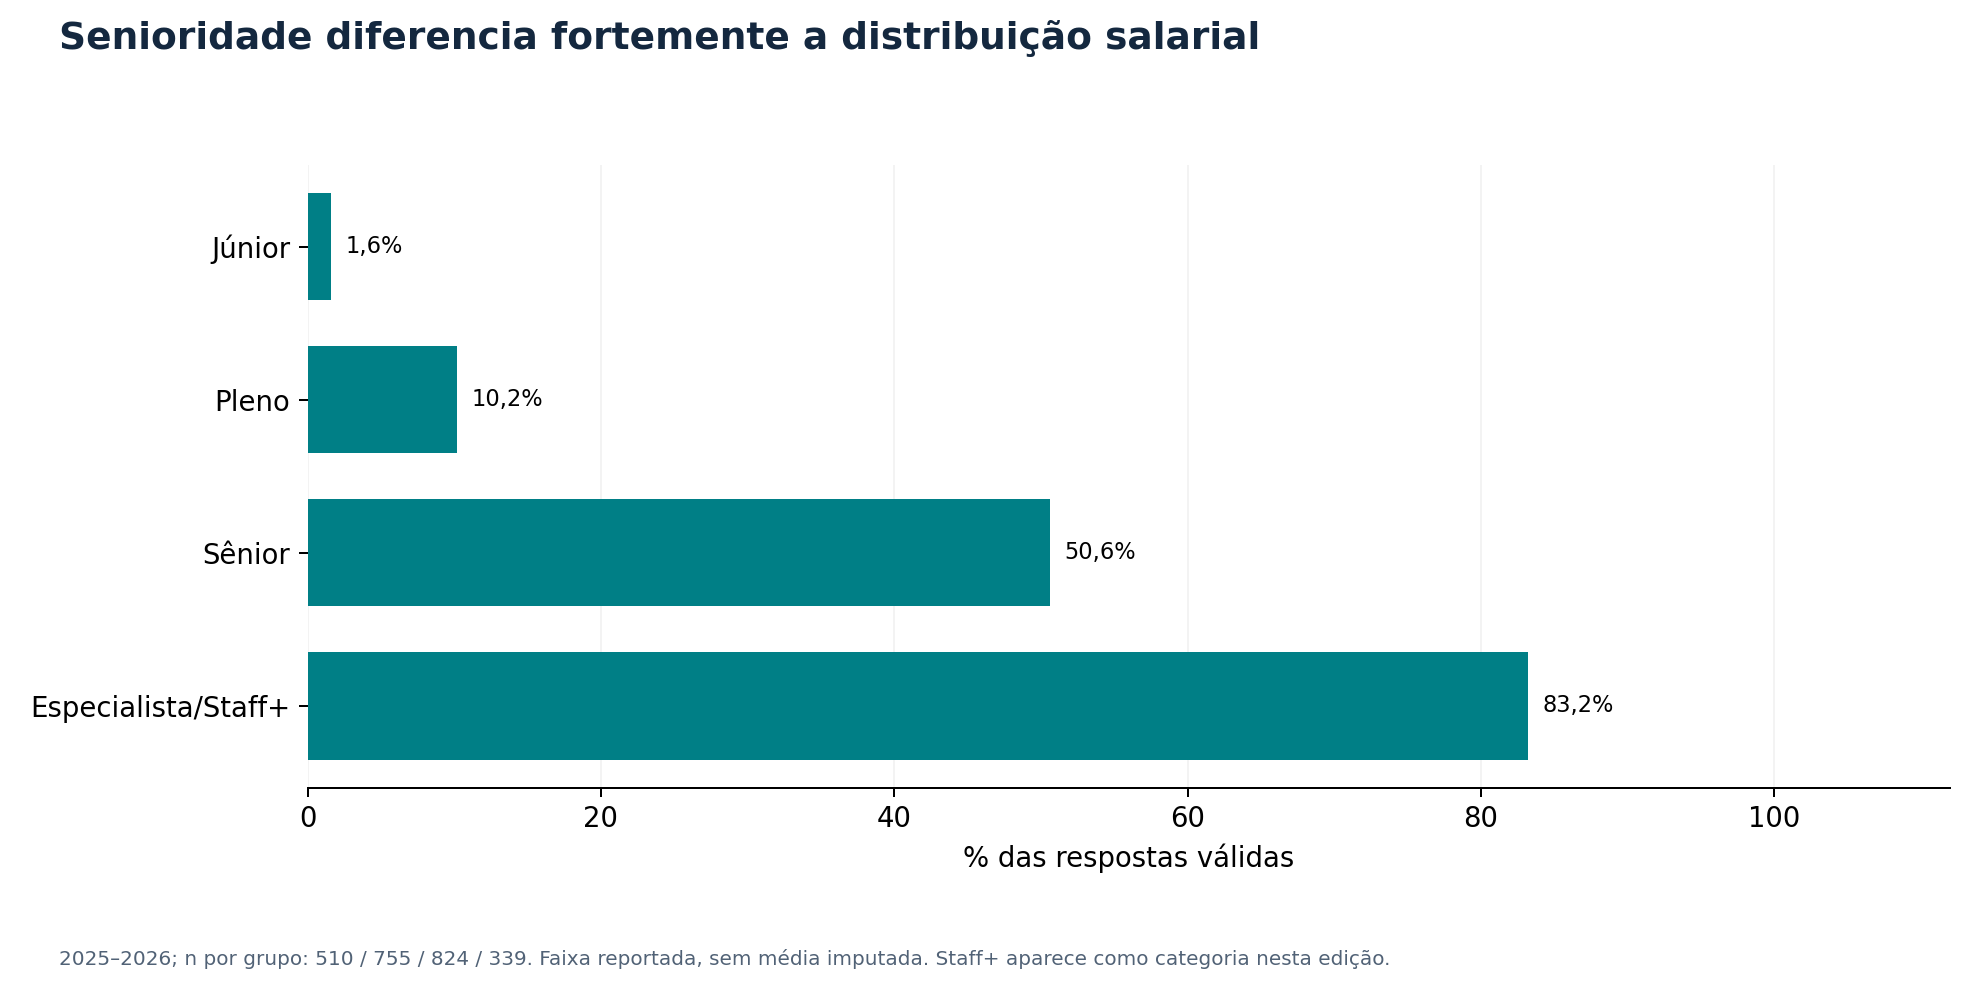

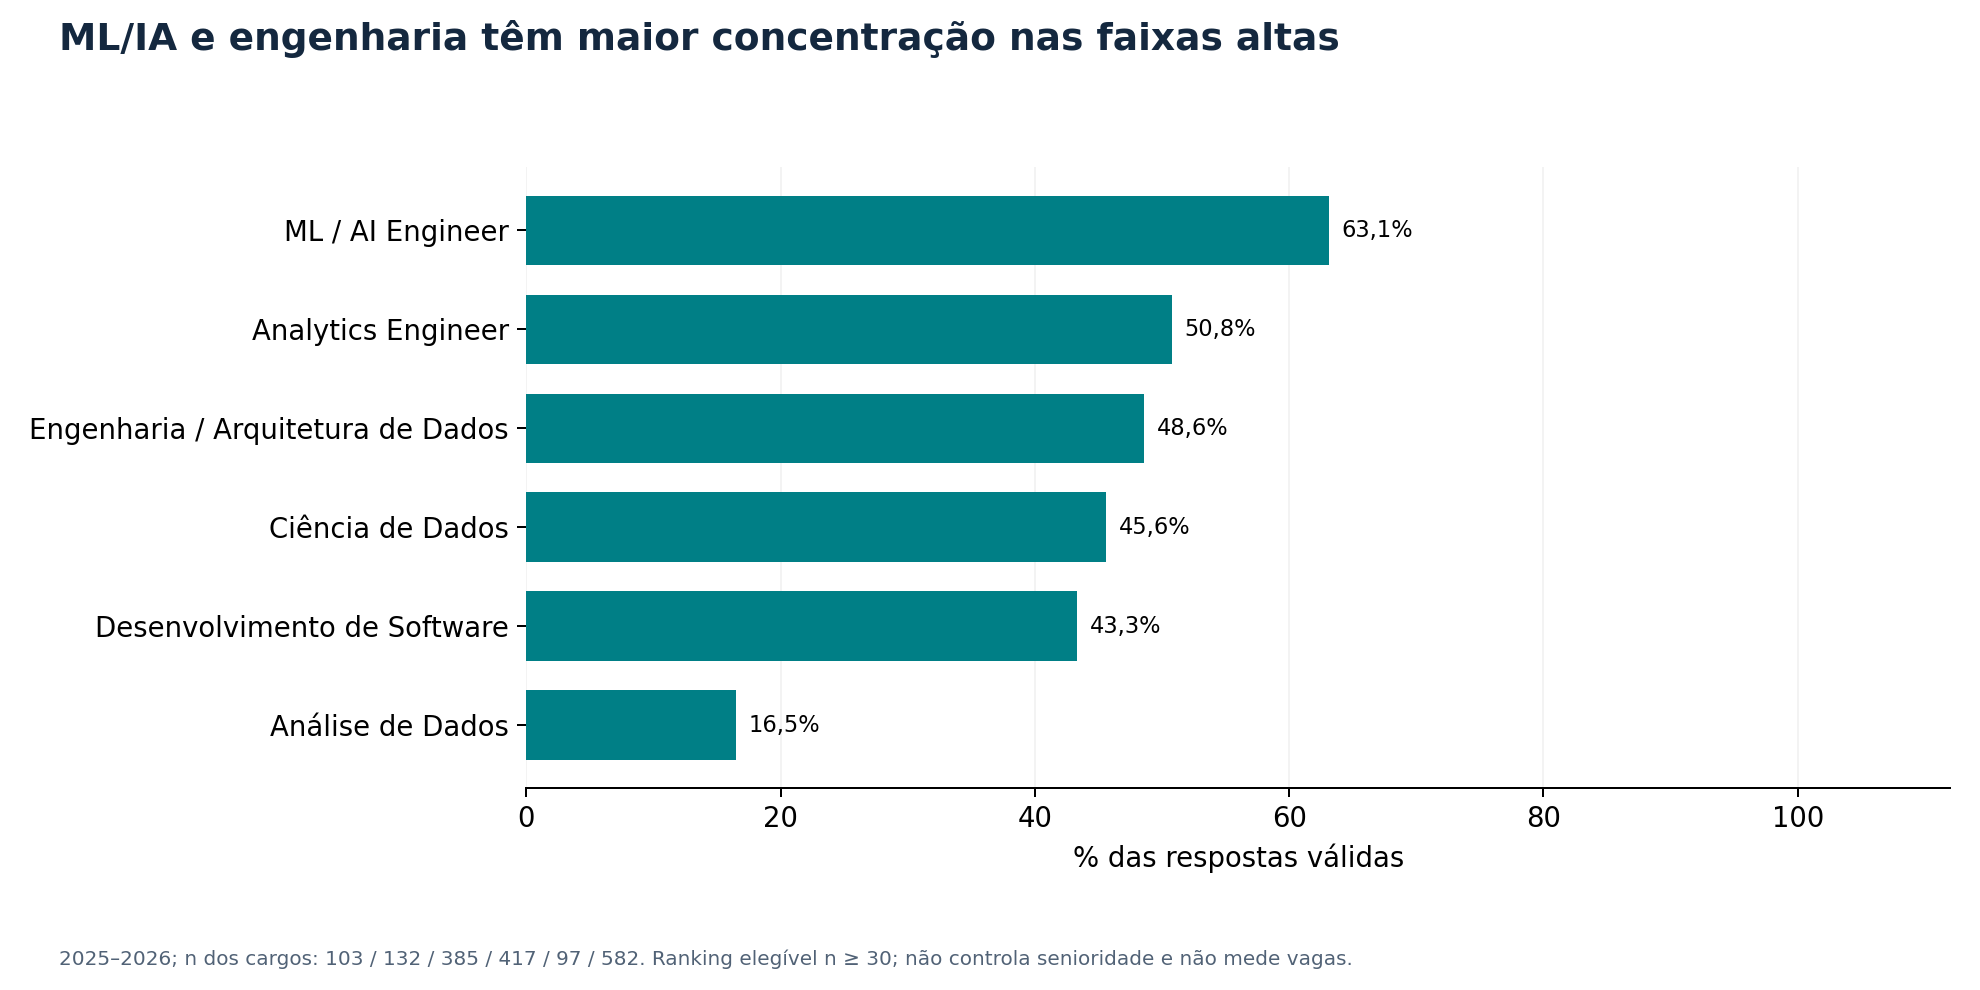

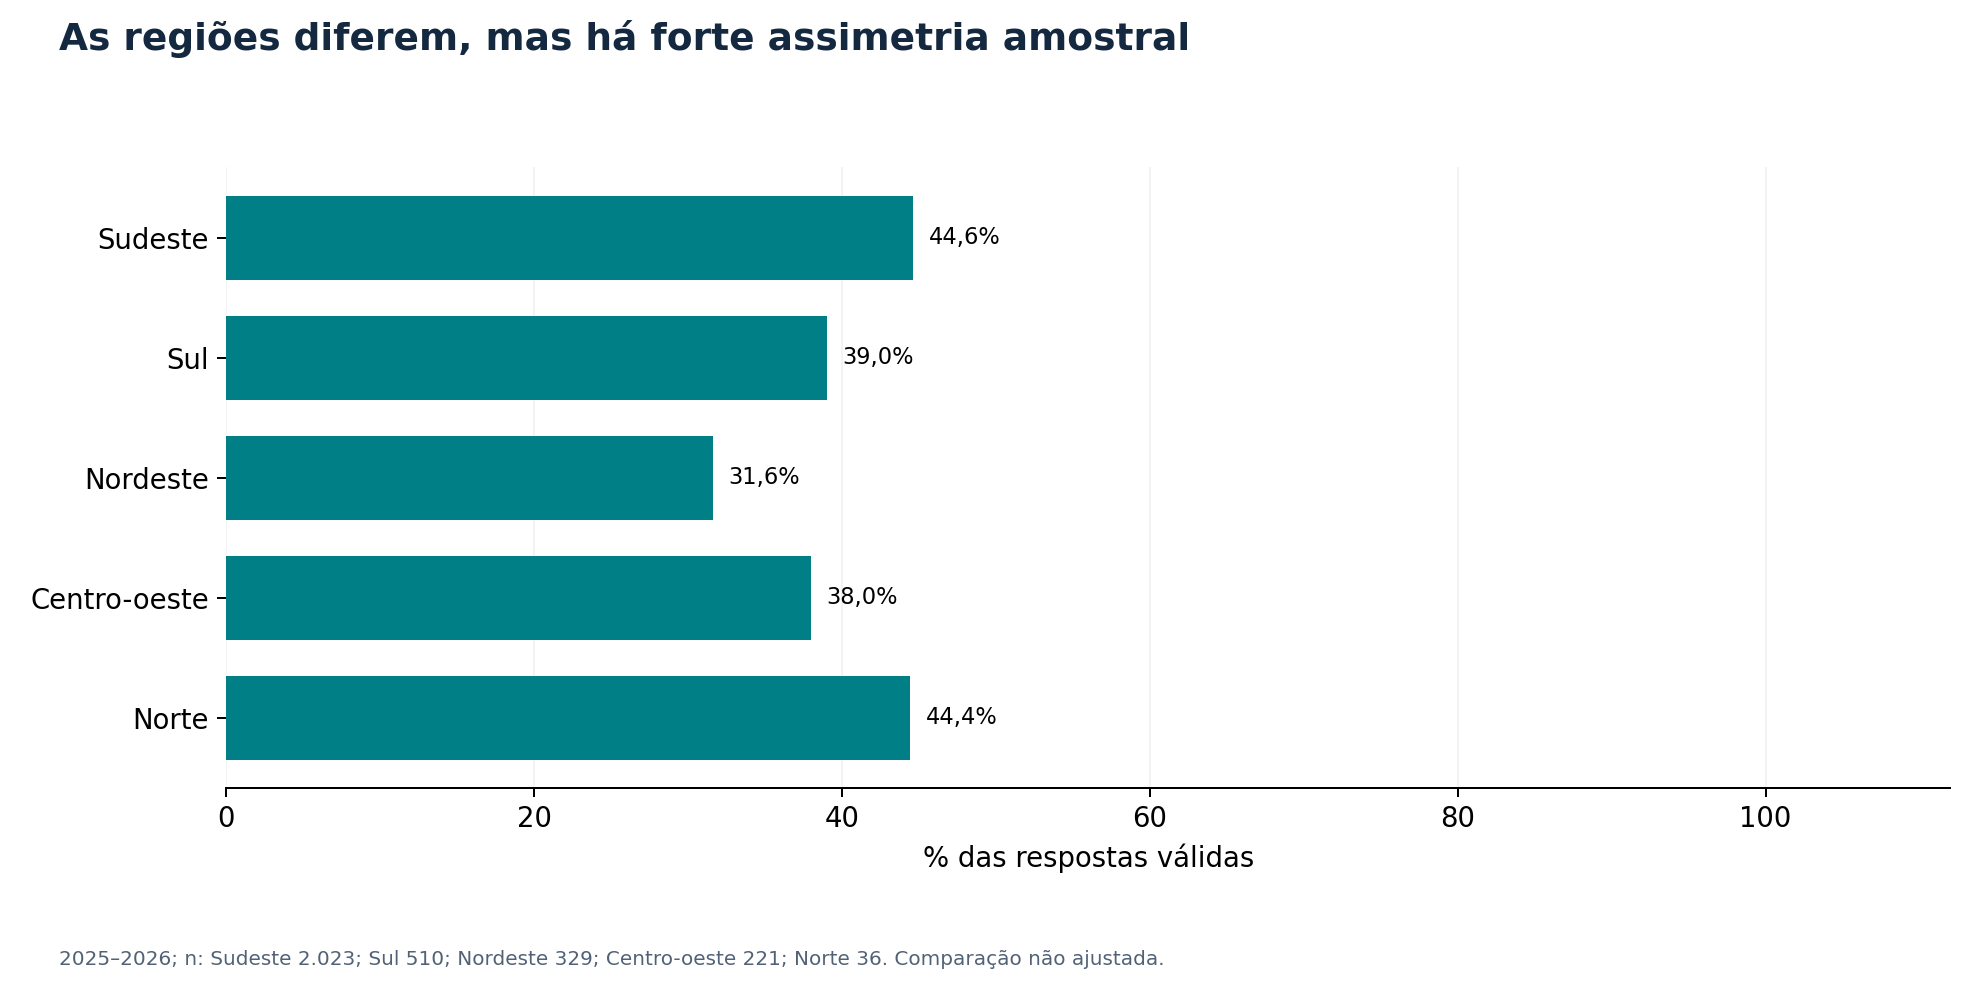

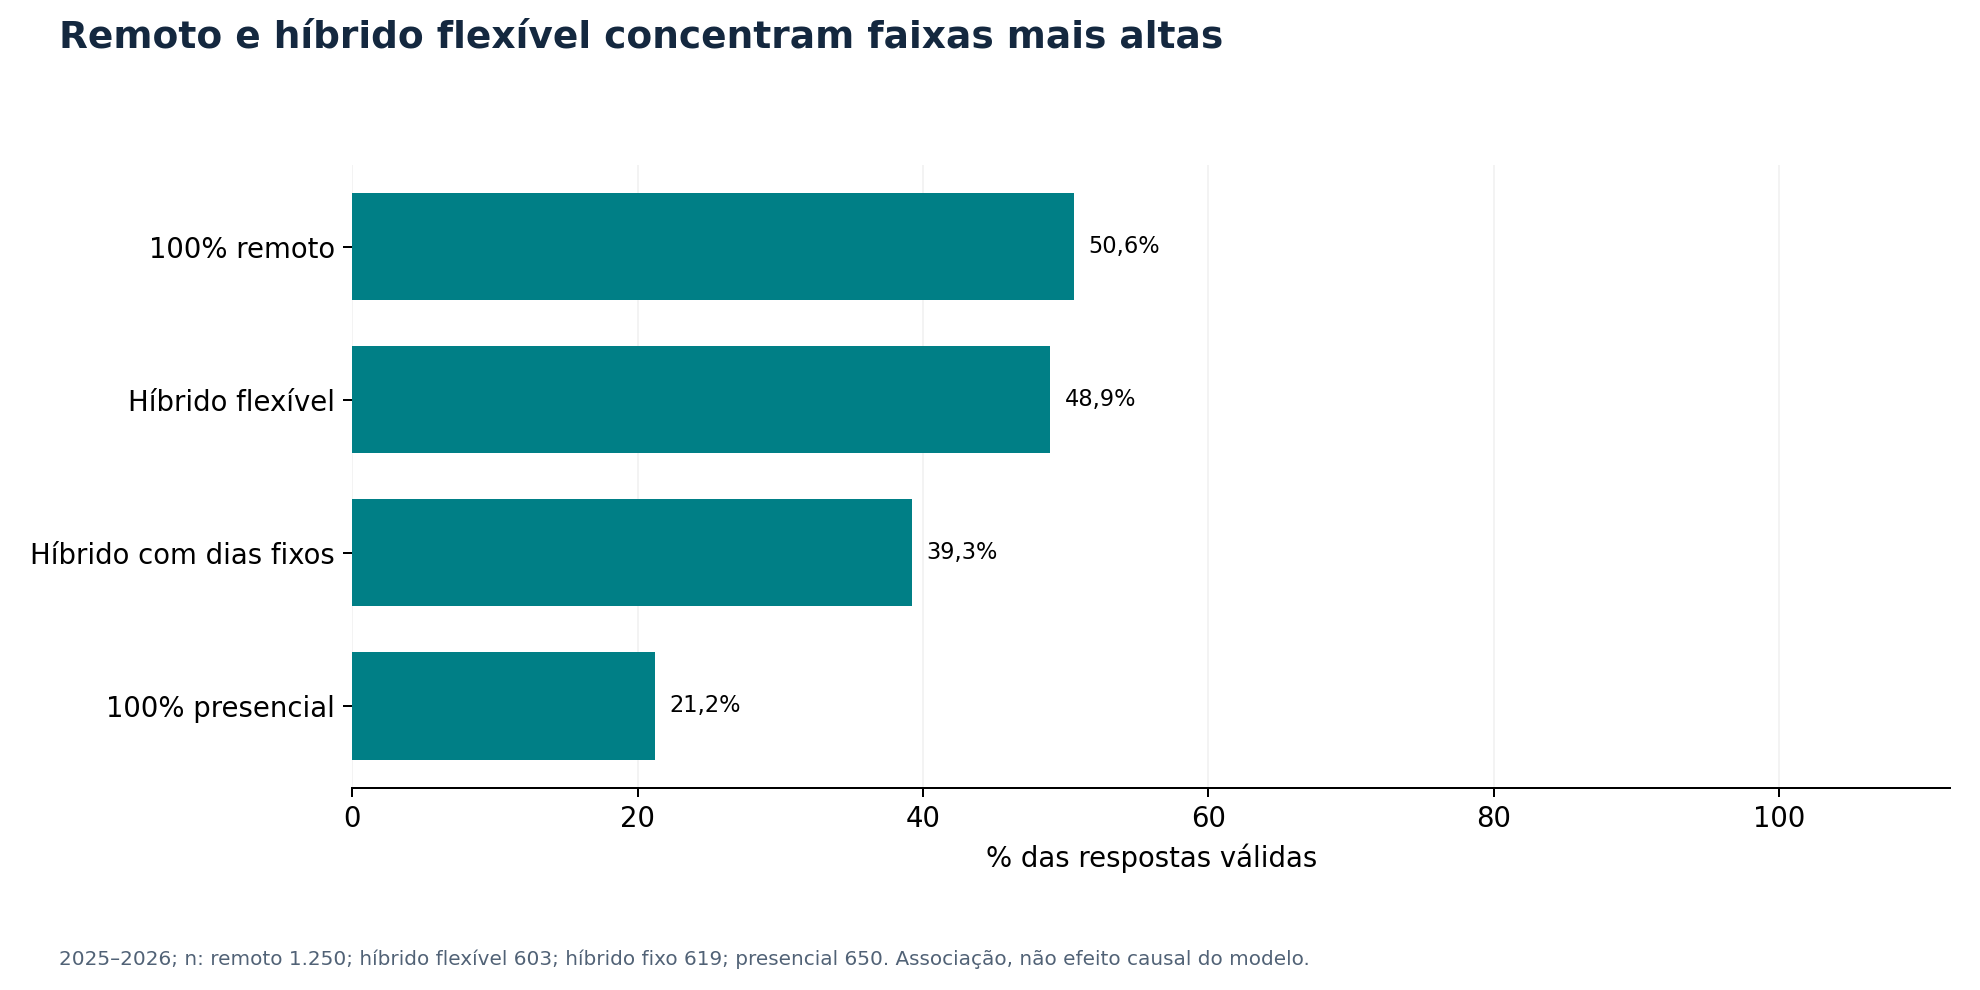

,cargo,senioridade,n,n_alto,proporcao
1,Analista de BI/BI Analyst,Júnior,57,1.0,0.017544
2,Analista de BI/BI Analyst,Pleno,81,3.0,0.037037
3,Analista de BI/BI Analyst,Sênior,57,12.0,0.210526
4,Analista de Dados/Data Analyst,Especialista/Staff+,59,37.0,0.627119
5,Analista de Dados/Data Analyst,Júnior,143,0.0,0.000000
6,Analista de Dados/Data Analyst,Pleno,204,9.0,0.044118
7,Analista de Dados/Data Analyst,Sênior,176,50.0,0.284091
10,Analista de Negócios/Business Analyst,Pleno,52,1.0,0.019231
11,Analista de Negócios/Business Analyst,Sênior,48,10.0,0.208333
17,Analytics Engineer,Pleno,41,9.0,0.219512


In [6]:
display(salarios.query("edicao_pesquisa == '2025-2026' and dimensao == 'cargo' and denominador >= 30").sort_values('percentual', ascending=False))
for nome in ['05_senioridade','06_cargos','07_salario_regiao','08_salario_modelo']:
    display(Image(filename=str(BASE/'graficos'/(nome+'.png')), width=900))
# Cruzamento adicional para examinar composição sem afirmar causalidade.
cruzamento = brasil.query("edicao_pesquisa == '2025-2026'").dropna(subset=['cargo','senioridade','salario_alto']).groupby(['cargo','senioridade']).salario_alto.agg(n='size', n_alto='sum', proporcao='mean').reset_index()
display(cruzamento[cruzamento.n.ge(30)].sort_values(['cargo','senioridade']))

## 5. Tecnologias: distinguir uso e preferência
O bloco SQL/Python de 2025–2026 tem cabeçalho de preferência; o bloco cloud de 2023 também. Por cautela, usamos 2024 para adoção de SQL/Python e 2025–2026 para adoção de cloud/BI. Múltipla escolha: percentuais não precisam somar 100%.

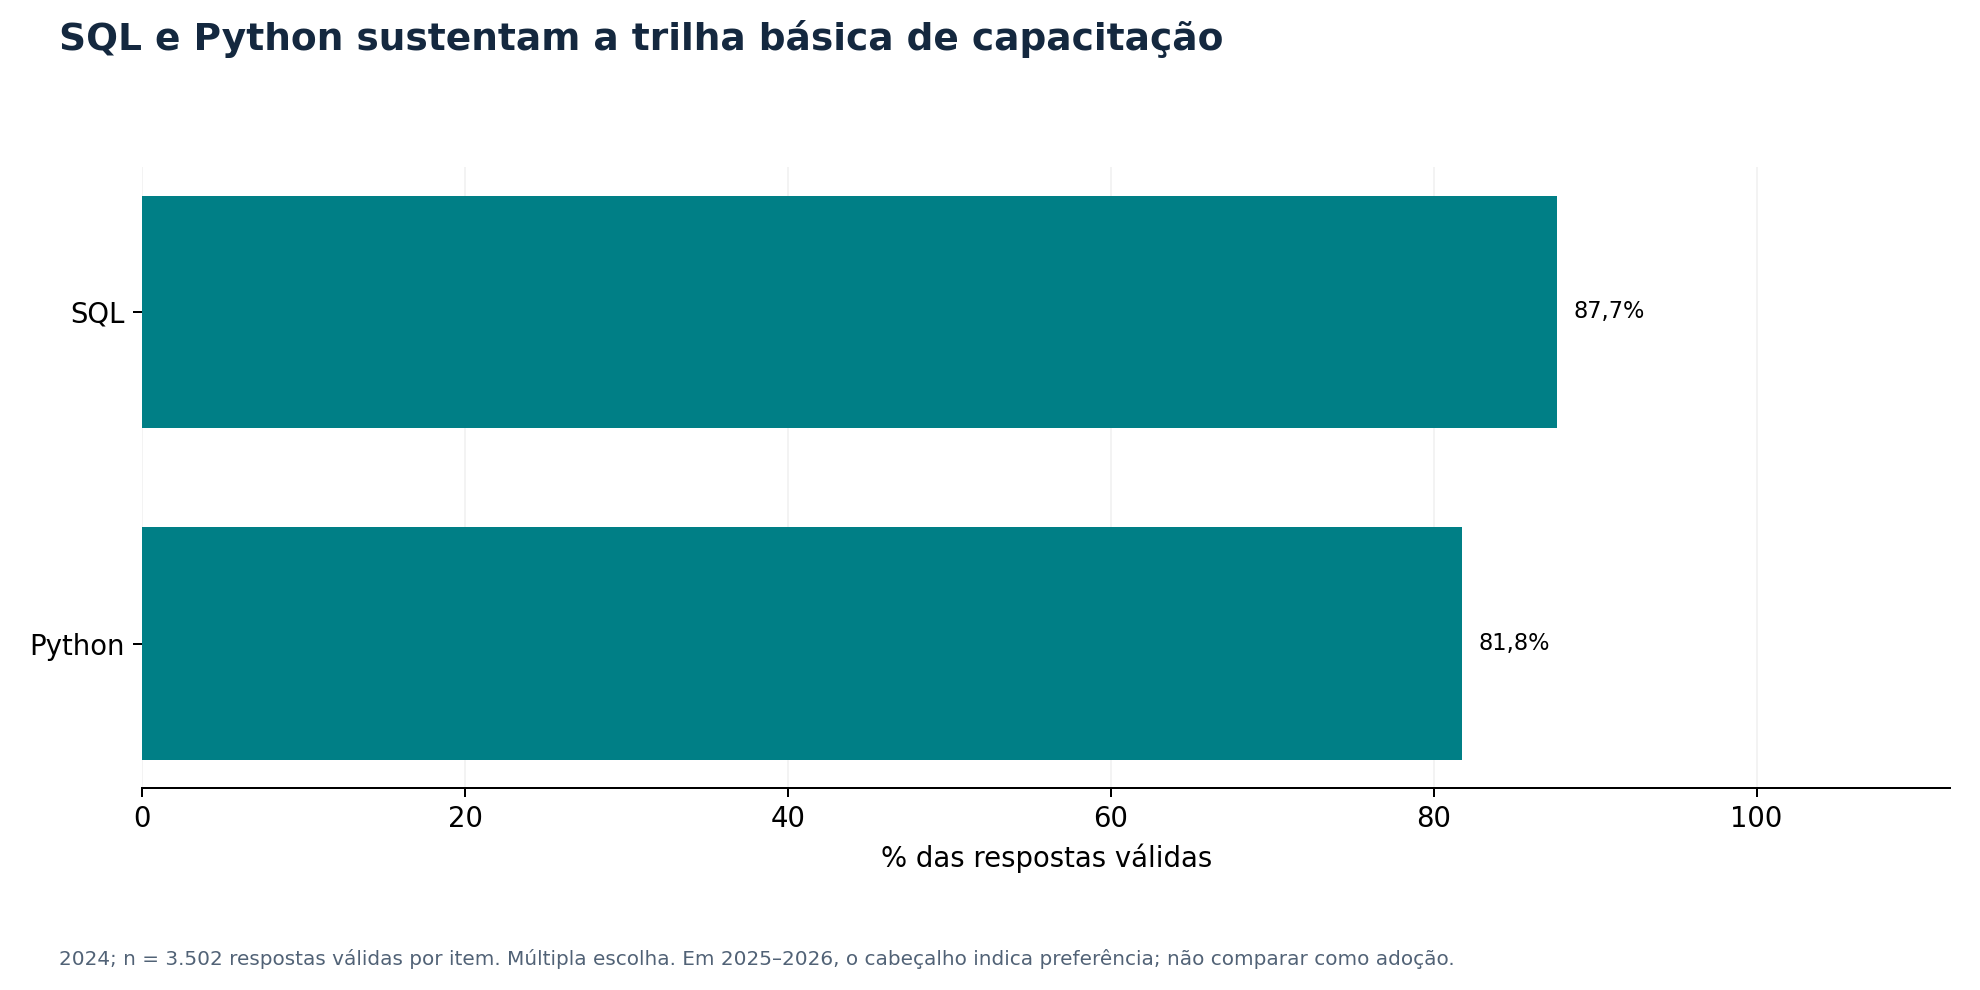

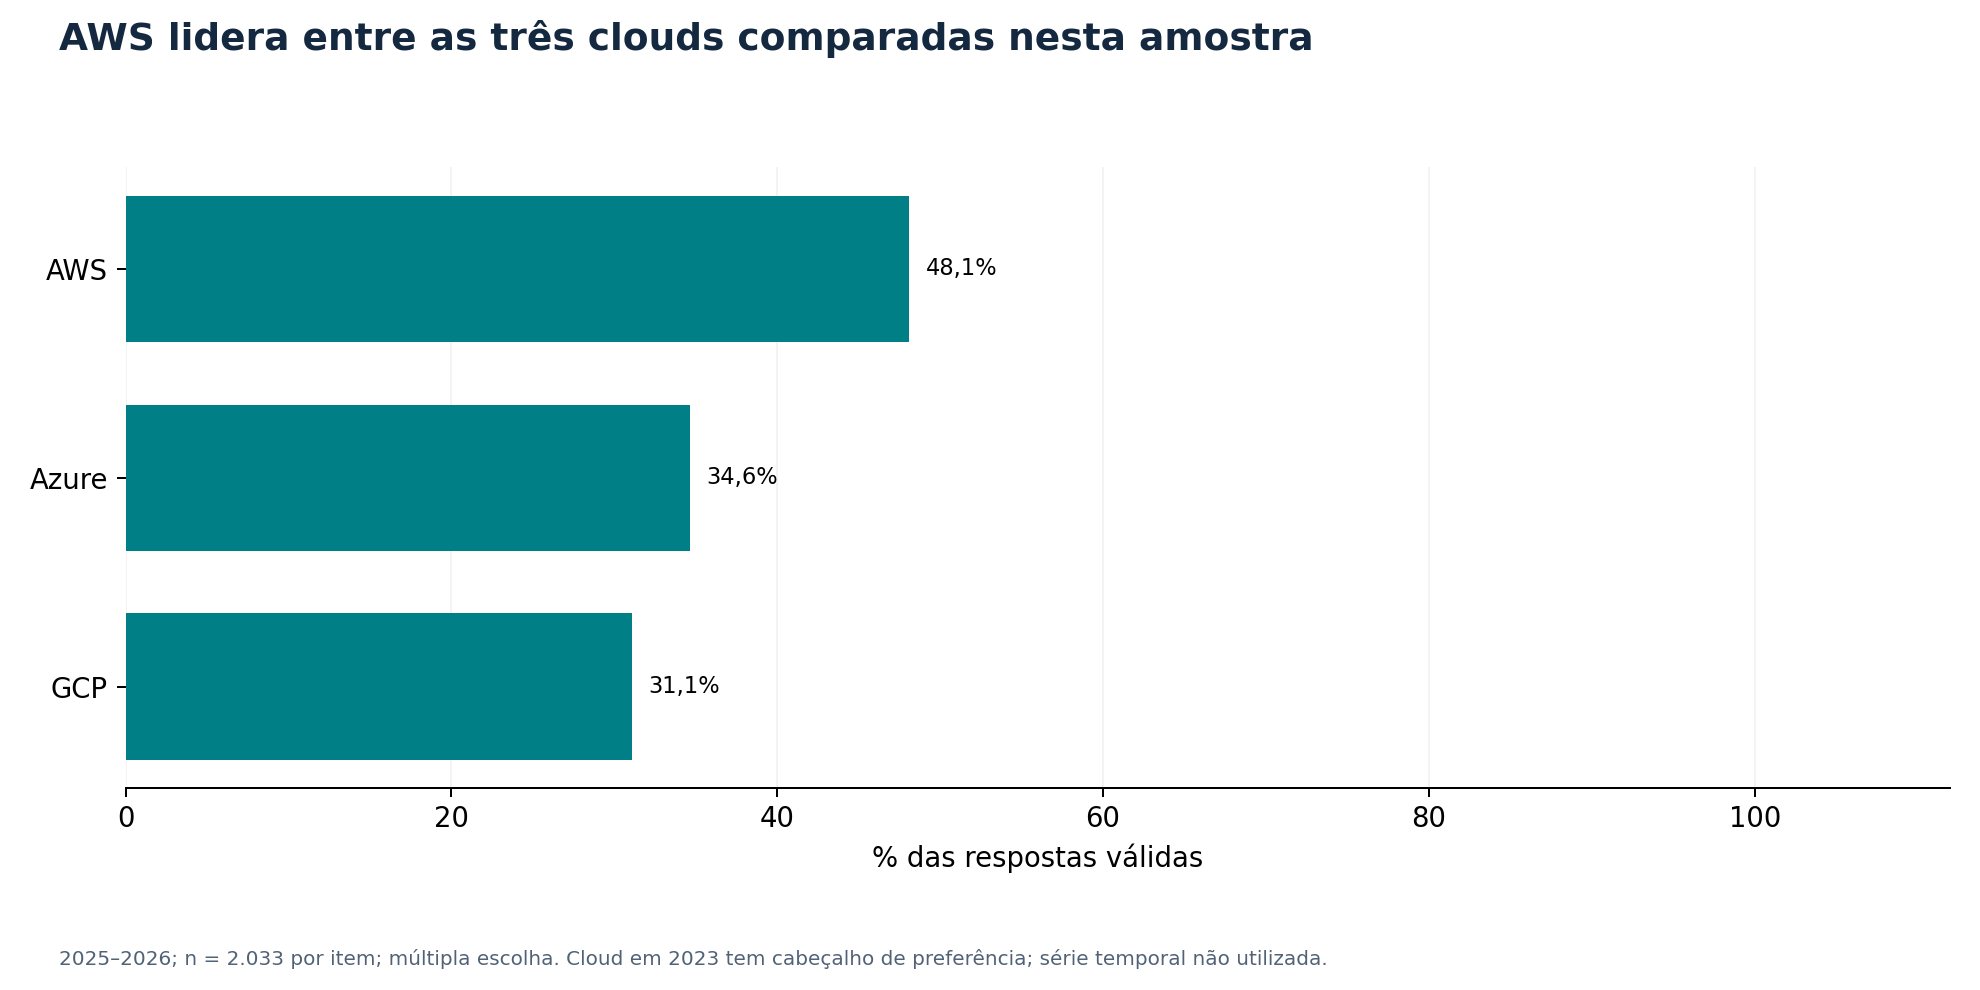

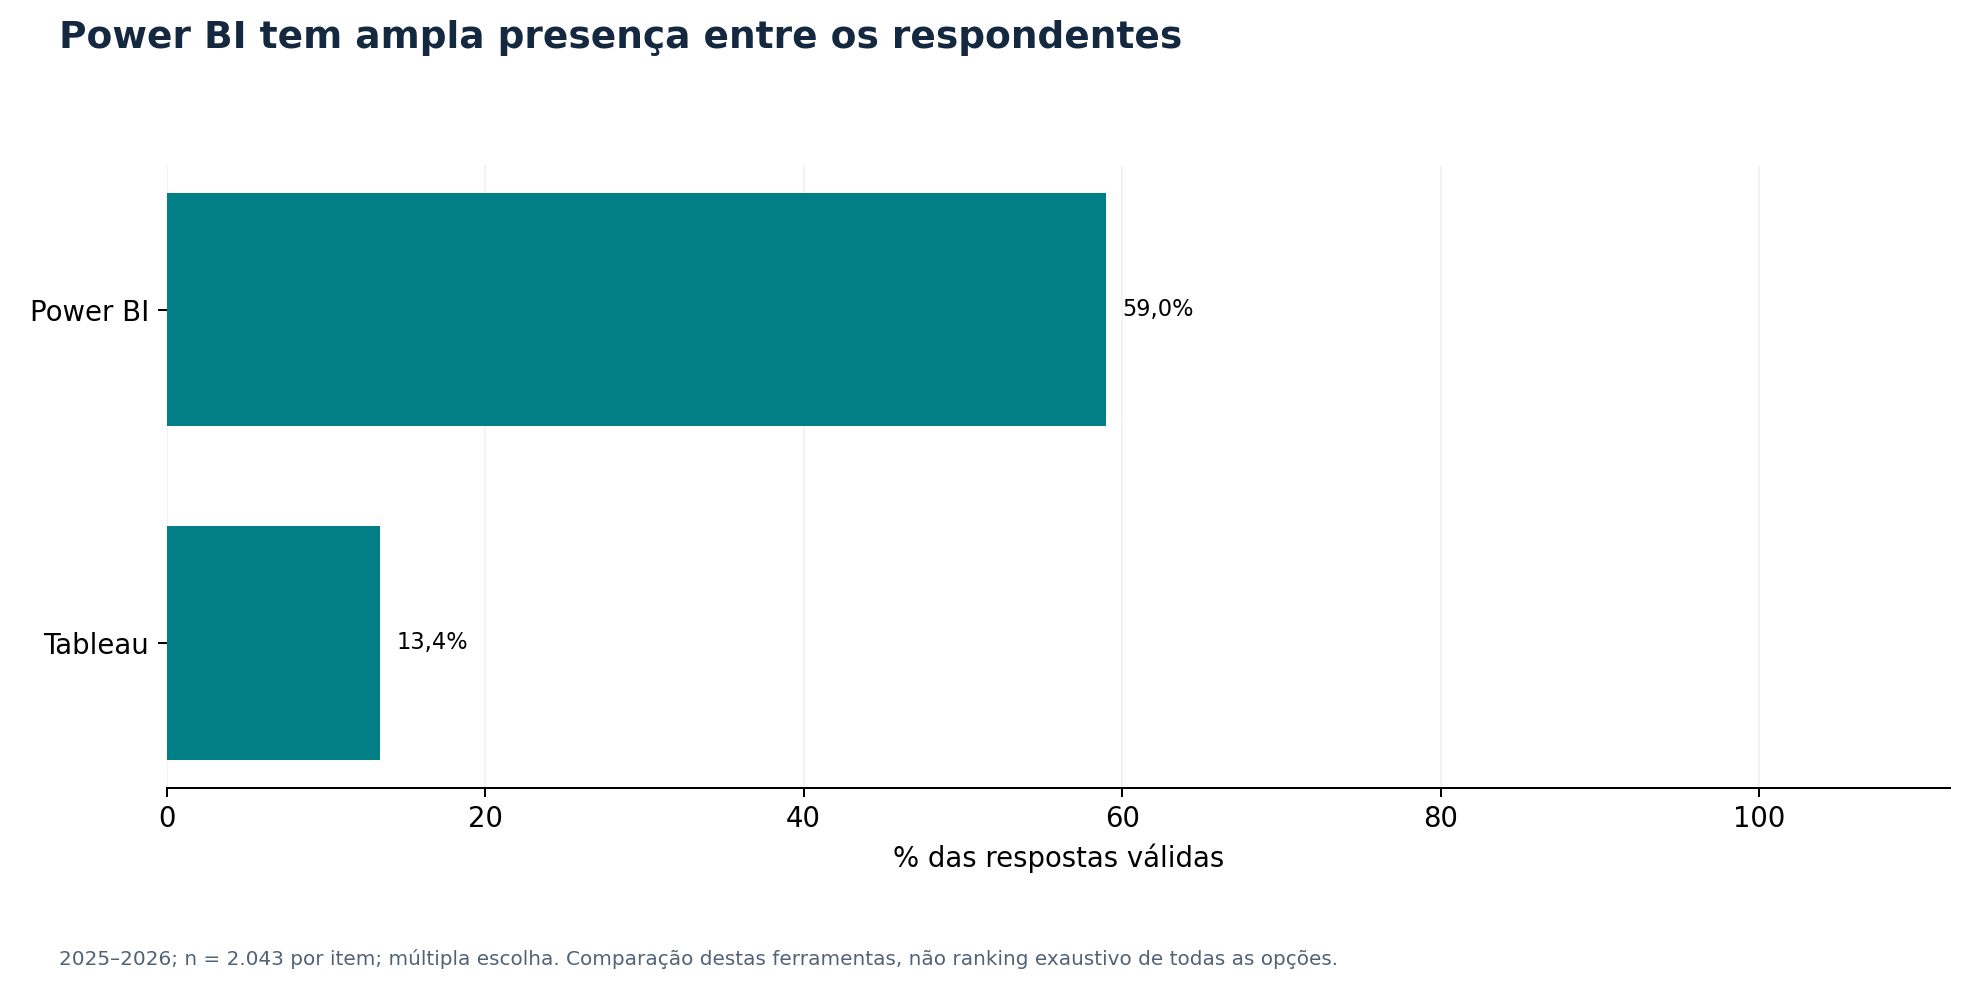

In [7]:
for nome in ['09_linguagens_2024','10_cloud','11_bi']:
    display(Image(filename=str(BASE/'graficos'/(nome+'.png')), width=900))

## 6. IA: uso, financiamento, governança e impacto
Uso deriva das alternativas de uso positivas; respostas contraditórias com “não uso” ficam fora do denominador. O resultado com LLMs é percepção de respondentes do bloco de gestores, não ROI auditado nem contagem de empresas únicas.

,edicao_pesquisa,indicador,n,denominador,percentual
0,2023,ia_usa,2965,3671,80.768183
1,2023,ia_paga_empresa,239,3697,6.464701
4,2023,ia_centralizada,389,3697,10.522045
15,2024,ia_usa,3297,3518,93.718022
16,2024,ia_paga_empresa,677,3531,19.173039
19,2024,ia_centralizada,746,3531,21.127159
30,2025-2026,ia_usa,1999,2038,98.086359
31,2025-2026,ia_paga_empresa,866,2043,42.388644
34,2025-2026,ia_centralizada,734,2043,35.927558


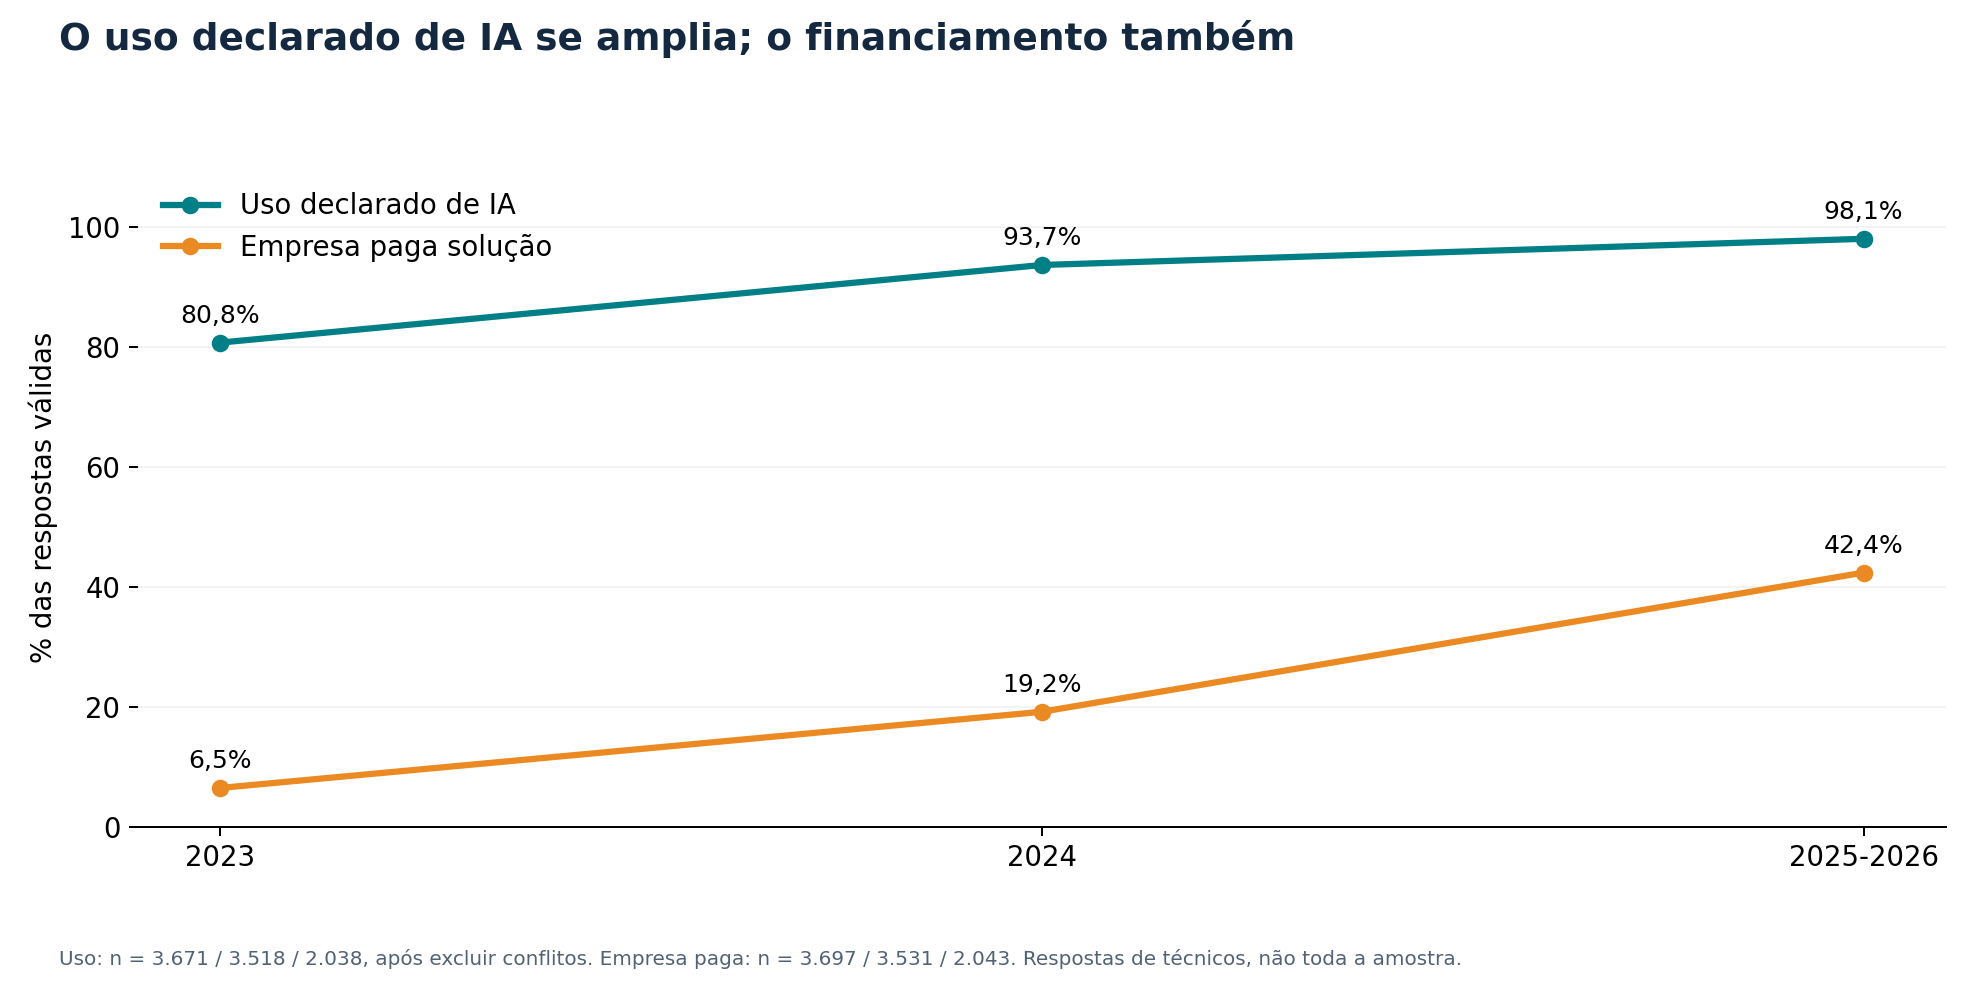

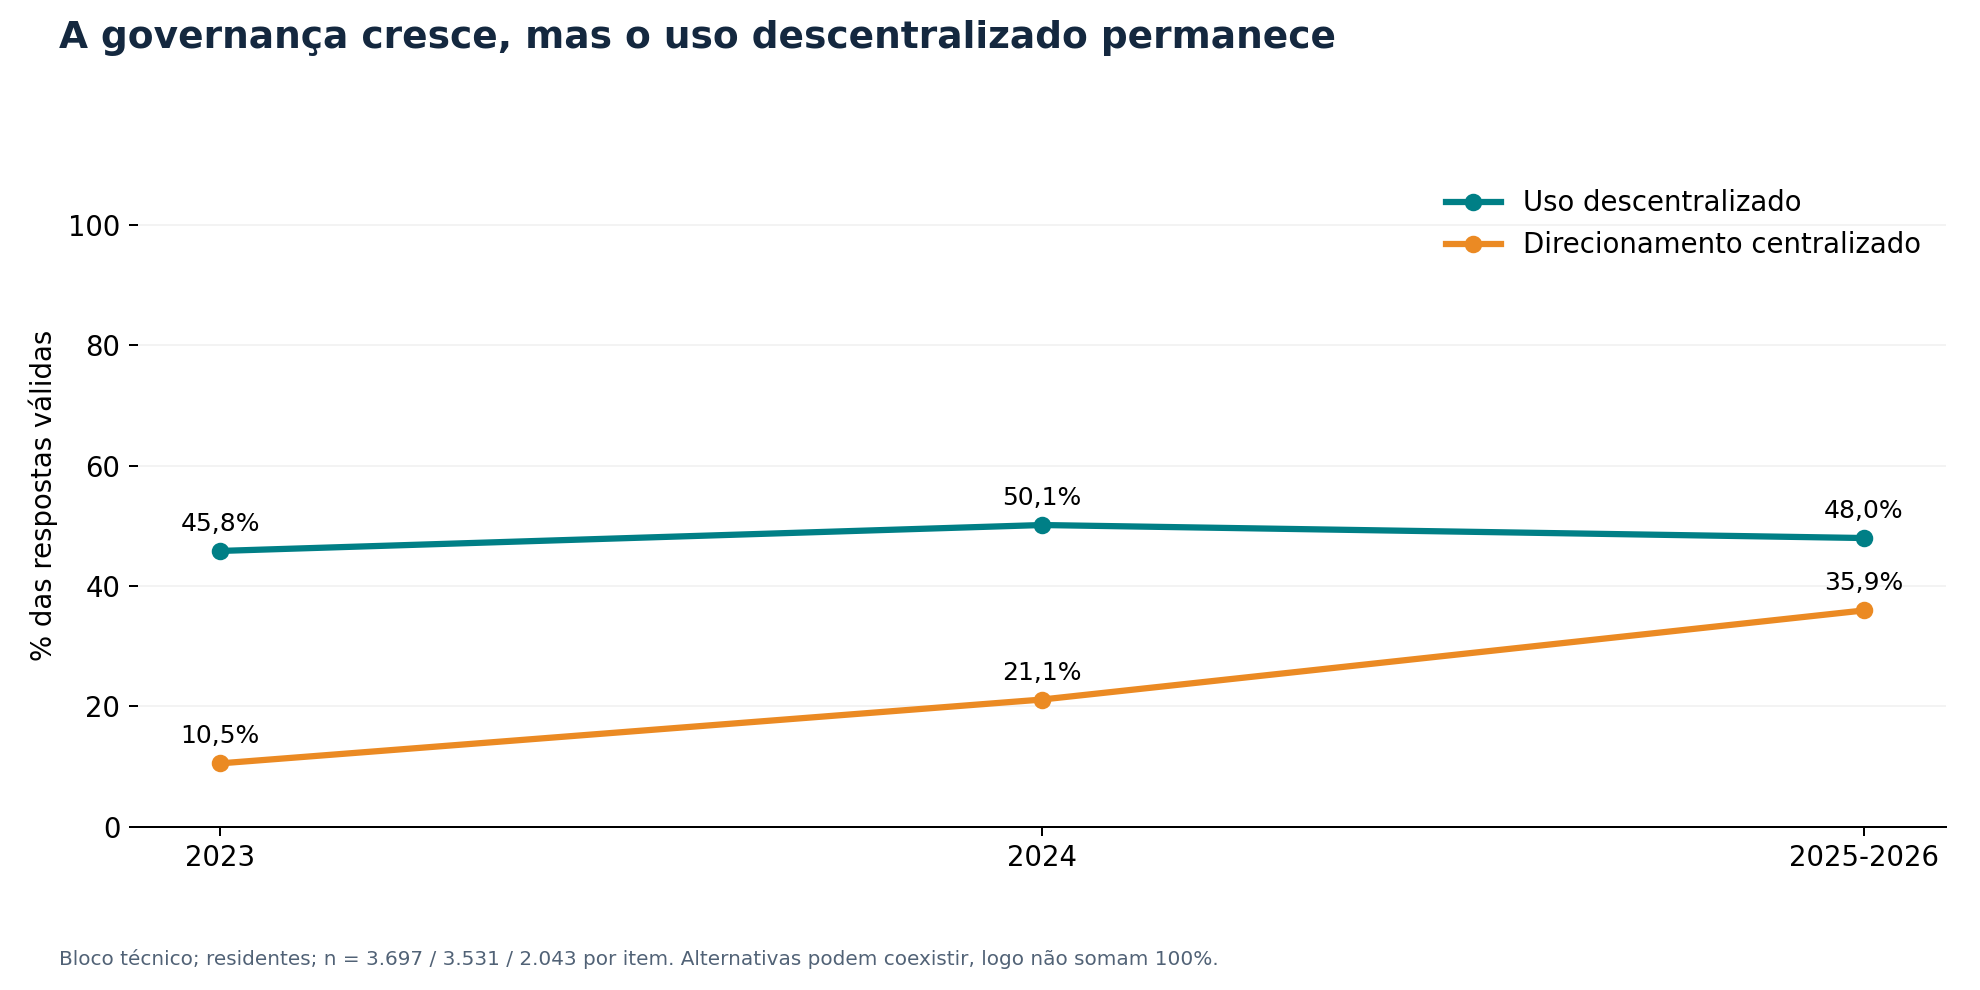

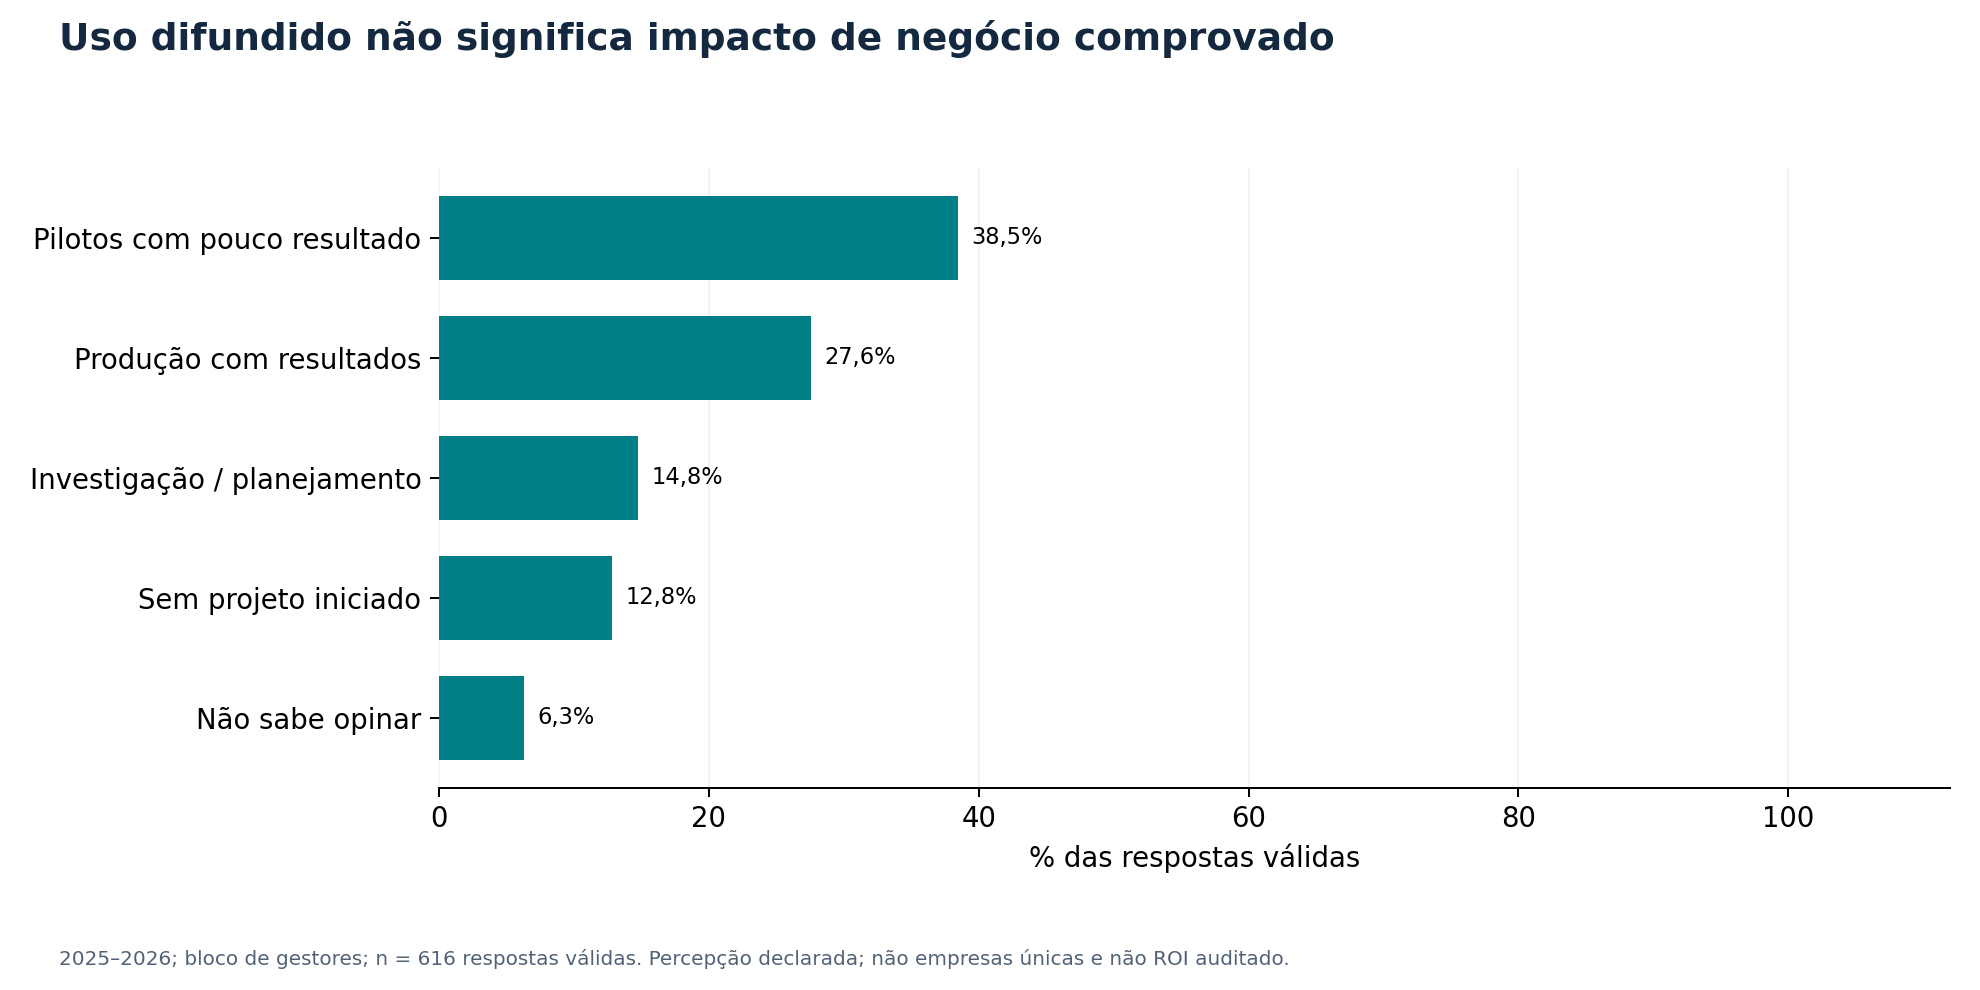

In [8]:
display(indicadores[indicadores.indicador.isin(['ia_usa','ia_paga_empresa','ia_centralizada'])])
for nome in ['12_ia','13_governanca','14_impacto']:
    display(Image(filename=str(BASE/'graficos'/(nome+'.png')), width=900))

## 7. Recomendações para a instituição financeira
1. Calibrar faixas por cargo/senioridade e combinar contratação especializada com trilhas internas.
2. Testar flexibilidade e monitorar aceite de ofertas e retenção.
3. Monitorar representação e progressão por gênero, sem atribuir causalidade a diferenças brutas.
4. Capacitar SQL/Python, engenharia, qualidade de dados e cloud.
5. Financiar ferramentas aprovadas de IA e medir pilotos com baseline de tempo, custo e qualidade.

O plano de 90 dias é uma proposta executiva. Metas numéricas precisam de baseline interno; não foram inventadas a partir da pesquisa.

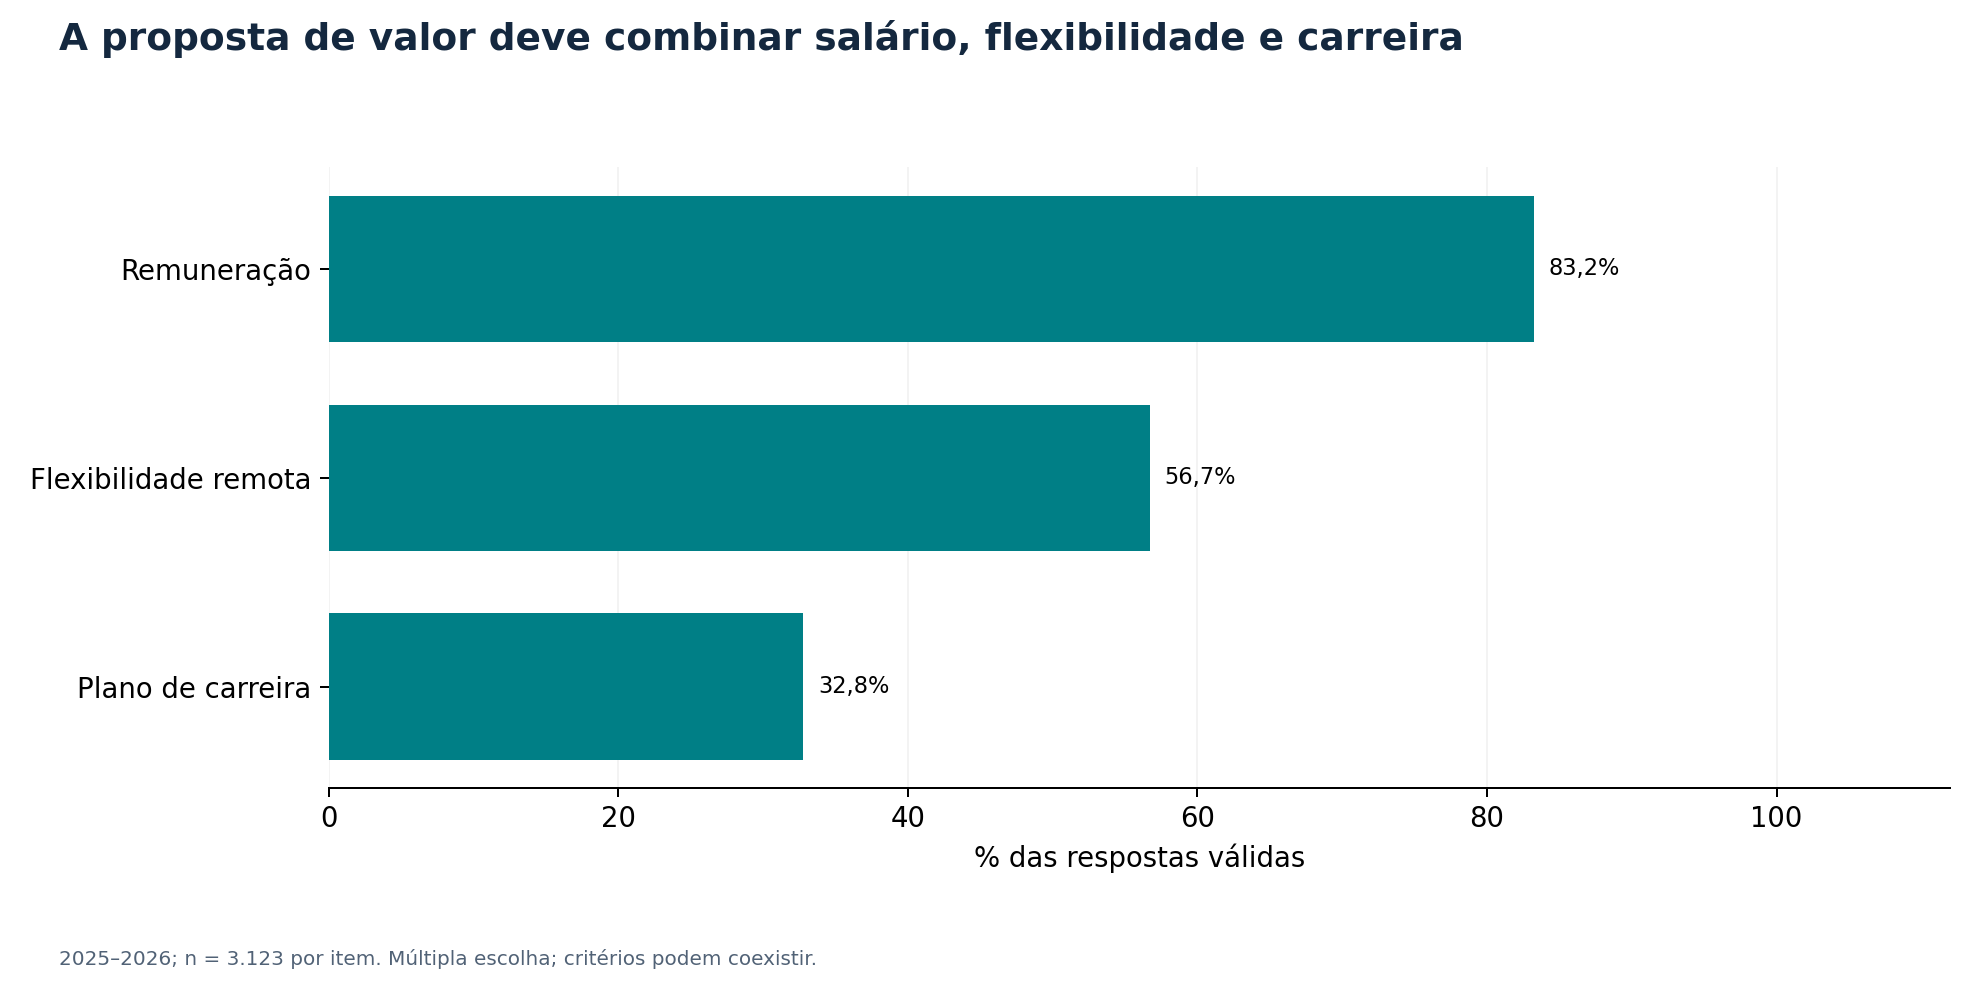

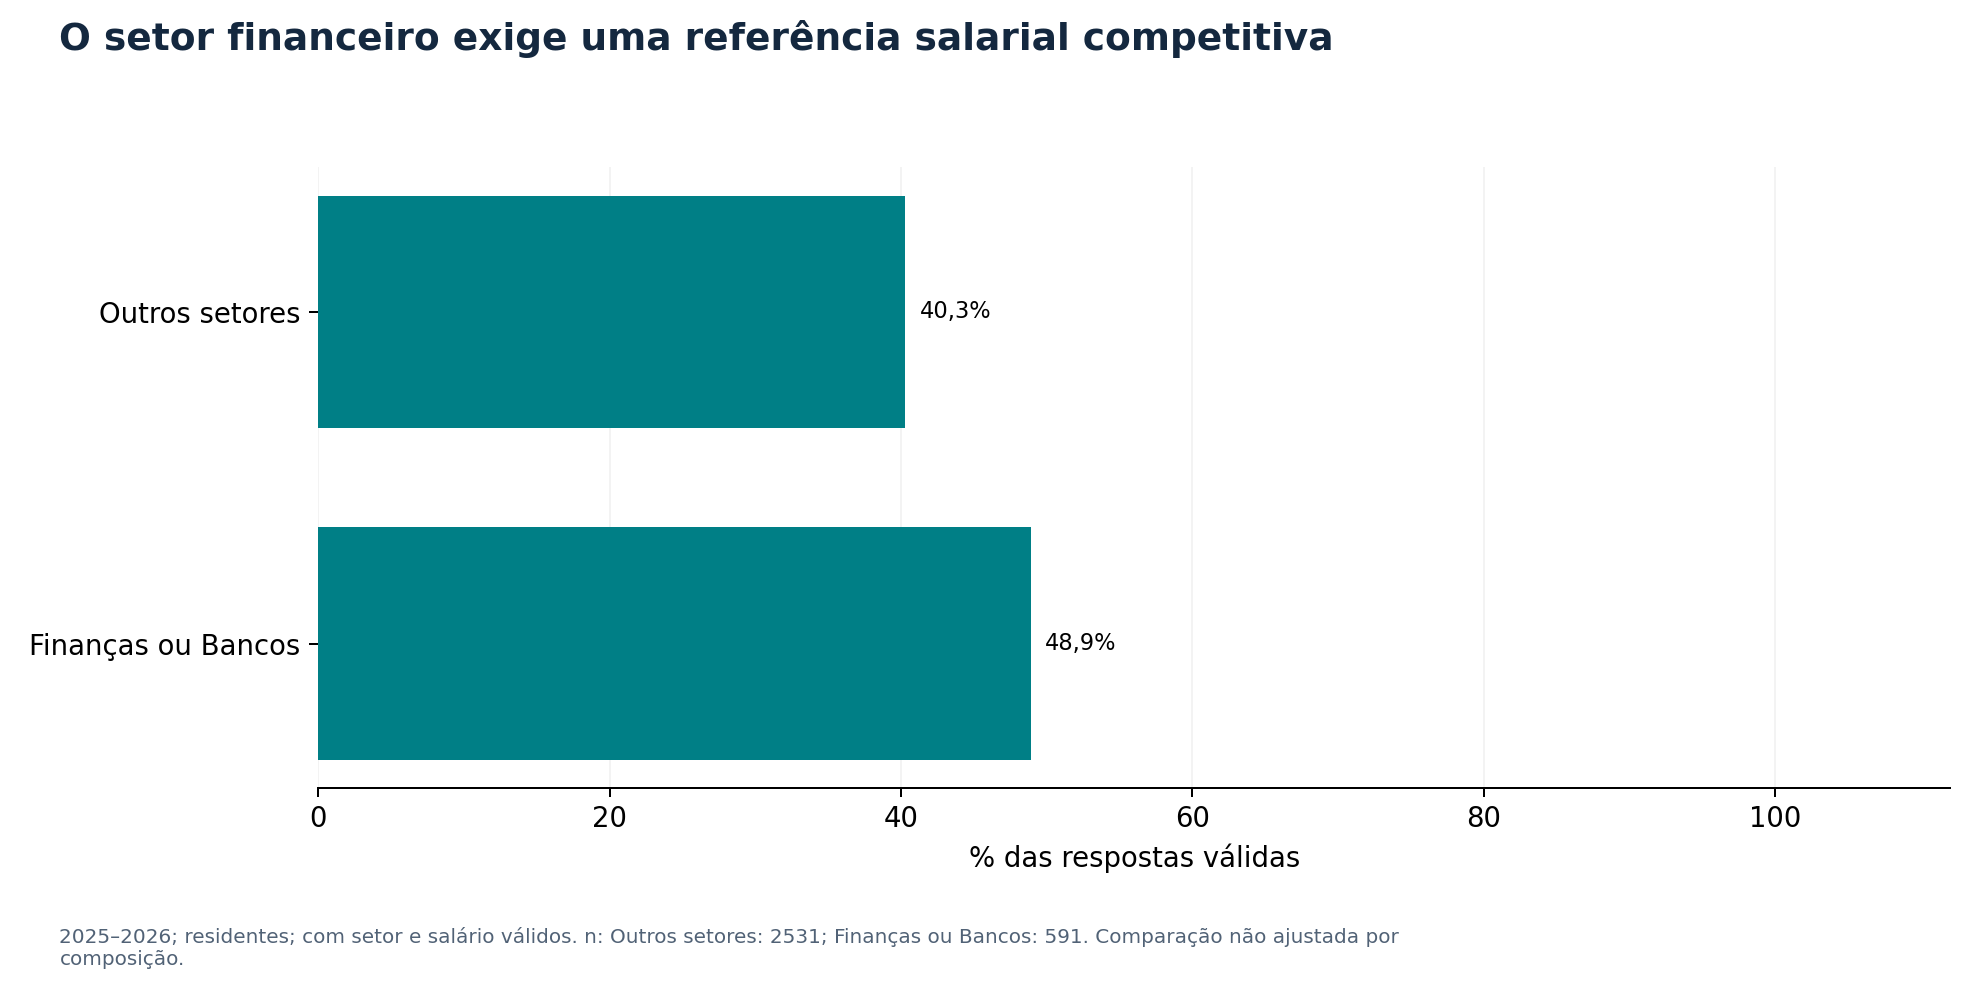

In [9]:
for nome in ['15_atracao','16_financas']:
    display(Image(filename=str(BASE/'graficos'/(nome+'.png')), width=900))